# EXP-COMBINED-3CLASSIFIERS-YOLO26S-V04-037 — Kết hợp YOLO26s với ba mô hình phân loại theo cùng một chế độ

**Mục tiêu.** Bảng 4.13 hiện đặt cạnh nhau ba con số không cùng điều kiện:
- DenseNet121 + YOLO26s: gộp 5 seed, detector V04-001.
- ResNet50 + YOLO26s: bộ phân loại EXP-032 (không phải mô hình ở mục 4.1), detector V04-002, BOX_CONF 0,15.
- ViT (DeiT-S) + YOLO26s: trung bình ± SD theo từng seed, quy trình kết hợp khác (lọc rò rỉ dHash, chia fold ngẫu nhiên, đặc trưng YOLO ở conf ≥ 0,25, log-xác suất, không temperature).

Notebook này chạy lại **phần kết hợp** cho cả ba mô hình theo **một** quy trình duy nhất, chính là quy trình đã mô tả ở mục 3.7.5 và đã dùng trong EXP-035:

| Thành phần | Dùng chung cho cả ba mô hình |
|---|---|
| Bộ phân loại | DenseNet121 = EXP-035 (giống ứng dụng); ResNet50 = EXP-031 (mục 4.1.2); ViT (DeiT-S) = EXP-016 (mục 4.1.3) |
| Chế độ chính | **gộp 5 seed** (trung bình xác suất của 5 seed), **một** bộ kết hợp cho mỗi quy tắc |
| Bằng chứng YOLO | YOLO26s `EXP-Y26S-NEG-V04-001`, đúng tệp `detector_evidence_*.csv` của EXP-035 (conf ≥ 0,05, NMS IoU 0,7, 640 px) |
| Tập fit bộ kết hợp | Validation sạch 1.361 ảnh (loại ảnh gần trùng ảnh train YOLO NEG_V04 theo pixel/pHash) |
| Chọn `C` | GroupKFold 5 fold theo nhóm pHash (cài đặt tất định, cùng fold cho cả ba mô hình), lưới {0,1; 0,3; 1; 3; 10}, tiêu chí log-loss |
| Hiệu chỉnh | temperature scaling + ngưỡng từ chối (độ chính xác chọn lọc ≥ 98%) trên dự đoán ngoài fold |
| Quy tắc | F0 (chỉ mô hình phân loại), F3a (bộ kết hợp, chỉ 5 xác suất), F3b (bộ kết hợp, chỉ 9 đặc trưng YOLO), F3 (cả 14 đặc trưng, quy tắc mặc định) |

Ngoài chế độ gộp, notebook chạy thêm **chế độ theo từng seed** (mỗi seed một bộ kết hợp, cùng quy trình) để có F0/F3 theo seed cho cả ba mô hình (Bảng PL.2, Hình 4.21).

**Không huấn luyện lại** mô hình phân loại hay YOLO. Notebook chỉ đọc dự đoán đã khóa (SHA-256 được kiểm tra) và ảnh Validation của Split13 để tính nhóm pHash. Chạy được trên CPU, local hoặc Colab.

**Kiểm tra tái lập bắt buộc (mục 7):** với DenseNet121 ở chế độ gộp, F0 phải trùng tuyệt đối EXP-035 (đầu vào giống hệt), còn Accuracy F3 trên Test và tập thực địa phải khớp EXP-035 trong dung sai 2 ảnh. Các fold được chia bằng một thuật toán tất định dùng chung cho cả ba mô hình.

**Giới hạn:** tập ảnh thực địa (Holdout 09, 126 ảnh) đã được xem trước, nên chỉ mang tính mô tả. Test được dùng cho nhiều phép so sánh. Bootstrap đo bất định do lấy mẫu ảnh, không đo biến động do seed.


In [1]:
# 1. Import và CONFIG — mọi lựa chọn của thí nghiệm nằm ở đây
import hashlib, io, json, math, os, platform, shutil, subprocess, sys, time, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import sklearn
from scipy.optimize import minimize_scalar
from scipy.stats import t as student_t
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, f1_score, log_loss,
                             precision_recall_fscore_support, top_k_accuracy_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
try:
    from IPython.display import display
except ImportError:
    display = print

EXPERIMENT_ID = "EXP-COMBINED-3CLASSIFIERS-YOLO26S-V04-037"
SEEDS = [42, 123, 2026, 3407, 7777]
CLASSES = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
CLASS_INDEX = {name: i for i, name in enumerate(CLASSES)}
CLASS_VN = {"anthracnose": "Thán thư", "healthy": "Lá khỏe", "leaf_miner": "Sâu vẽ bùa",
            "red_rust": "Rỉ đỏ", "not_cashew_leaf": "Không phải lá điều"}
DETECTOR_CLASSES = ["anthracnose", "leaf_miner", "red_rust"]
HOLDOUT_LABELS = CLASSES[:4]  # tập ảnh thực địa không có lớp not_cashew_leaf
SPLIT13_SHA256 = "e1647b72e10af04275dc760545f4ef17c9f44343ae119495b89ba1e3cd954e04"
DETECTOR = {"name": "EXP-Y26S-NEG-V04-001",
            "best_pt_sha256": "f9dc3fba1347b3213819f61abddb36b07e455112d4e6e8d57eeeeca8ab1b7f4a",
            "evidence": "detector_evidence_{validation,test,holdout}.csv của EXP-035 "
                        "(conf >= 0.05, NMS IoU 0.7, imgsz 640, rect=False, từng ảnh)"}
DRIVE_FOLDER_ID = "1DGKTnzsvVc60RIEn5lQgflR3s-loM24G"

MODELS = ["DenseNet121", "ResNet50", "ViT (DeiT-S)"]
SOURCES = {
    "DenseNet121": {
        "experiment": "EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04", "kind": "exp035",
        "note": "5 mô hình DenseNet121 của EXP-035, giống ứng dụng web",
        "archives": [{"name": "EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_ANALYSIS.zip",
                      "bytes": 22794692, "drive_file_id": "1o35xd-vrqE3LaAJBCxKesq3pIogBFbb_",
                      "sha256": "27b5ea684d99dc8b160e7eac0694ba1a7e647789f158807f576e14a1fe208aca"}]},
    "ResNet50": {
        "experiment": "EXP-RESNET50-TRANSFER-5SEEDS-031-256px-c954b7c4", "kind": "standard",
        "note": "mô hình ResNet50 ở mục 4.1.2, chọn theo Validation",
        "archives": [{"name": "EXP-RESNET50-TRANSFER-5SEEDS-031-256px-c954b7c4_ANALYSIS.zip",
                      "bytes": 36953579, "drive_file_id": None,
                      "sha256": "85151ff0dbb9aedce08ca8d1b13c136c23ceb6e23a8af81d1d50064e24f35167"}]},
    "ViT (DeiT-S)": {
        "experiment": "EXP-VIT-DEITSMALL-TRANSFER-LLRD-5SEEDS-016-256px-1192fd08", "kind": "standard",
        "note": "mô hình ViT (DeiT-S) ở mục 4.1.3 (LLRD)",
        # ANALYSIS được ưu tiên; FULL (3 GB) chỉ dùng khi đã có sẵn ở máy.
        "archives": [{"name": "EXP-VIT-DEITSMALL-TRANSFER-LLRD-5SEEDS-016-256px-1192fd08_ANALYSIS.zip",
                      "bytes": 36231548, "drive_file_id": None,
                      "sha256": "ee321110aaf7095ae1d4a43cb3f04b77ebdbdad9436553a306ebcd82b12a5945"},
                     {"name": "EXP-VIT-DEITSMALL-TRANSFER-LLRD-5SEEDS-016-256px-1192fd08_FULL.zip",
                      "bytes": 3060870225, "drive_file_id": None, "local_only": True,
                      "sha256": "e28040960babaaeab18c8cc892bb80c094fcc42a50c8c136590aefade6b5578f"}]},
}
ARCHIVE_OVERRIDES = {}  # ví dụ {"ResNet50": "/content/drive/MyDrive/....zip"}

# Ảnh Validation của Split13: chỉ dùng để tính nhóm pHash (không chạy mô hình).
SPLIT13 = {"name": "CashewData_Split (13).zip", "file_id": "1HUE5ObO1vW0mP2QjgsdObMuW4RVPzNk7",
           "bytes": 1470301553, "sha256": SPLIT13_SHA256}
SPLIT13_VAL_DIR_OVERRIDE = None
SPLIT13_VAL_CANDIDATES = [Path("D:/Study/KhoaLuanTotNghiep/Dataset/CashewData_Split (13)/CashewData_Split/val")]
INPUT_SEARCH_ROOTS = [Path.cwd(), Path("/content"), Path("/content/drive/MyDrive"),
                      Path("D:/Study/Training result dowload/deep model"),
                      Path("D:/Study/Training result dowload")]

EXPECTED = {"validation": 1452, "test": 685, "holdout": 126,
            "clean_validation": 1361, "phash_groups": 1350}  # số in ra trong EXP-035
KNOWN_DUPLICATES = {"holdout/healthy/real_healthy_40.jpg", "holdout/healthy/real_healthy_42.jpg"}
C_GRID = (0.1, 0.3, 1, 3, 10)
CV_FOLDS = 5
PHASH_HAMMING = 4
ABSTAIN_TARGET_ACCURACY = 0.98
BOOTSTRAP_REPS = 10000
BOOTSTRAP_SEED = 20261109
# Kiểm tra tái lập với EXP-035 (mục 7). Đầu vào phải trùng tuyệt đối: DenseNet121 gộp F0 đúng
# 659/685 ảnh Test và 105/126 ảnh thực địa (96,20% và 83,33%, mục 3.7.2 và Bảng 4.13).
EXPECTED_DENSENET_F0_CORRECT = {"test": 659, "holdout": 105}
# Cách chia fold của EXP-035 phụ thuộc phiên bản thư viện/CPU nên không tái lập được từng ảnh;
# Accuracy F3 trên Test/thực địa được phép lệch tối đa số ảnh này.
PARITY_F3_TOLERANCE_IMAGES = 2
PARITY_STRICT = True

IN_COLAB = Path("/content").is_dir() and "google.colab" in sys.modules
UPLOAD_TO_DRIVE = IN_COLAB

def project_root():
    if IN_COLAB:
        return Path("/content")
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "training_results").is_dir():
            return candidate
    return Path.cwd()

OUT_DIR = project_root() / "training_results" / "current_dataset" / EXPERIMENT_ID
CACHE_DIR = OUT_DIR.parent / f"{EXPERIMENT_ID}_cache"
for directory in (OUT_DIR, OUT_DIR / "aggregate", OUT_DIR / "figures", OUT_DIR / "frozen",
                  OUT_DIR / "predictions", OUT_DIR / "thesis_tables", CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
AGG, FIG, FROZEN = OUT_DIR / "aggregate", OUT_DIR / "figures", OUT_DIR / "frozen"
PRED, TABLES = OUT_DIR / "predictions", OUT_DIR / "thesis_tables"
ENVIRONMENT = {"python": sys.version.split()[0], "platform": platform.platform(),
               "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
               "matplotlib": matplotlib.__version__, "colab": IN_COLAB}
print(json.dumps(ENVIRONMENT, ensure_ascii=False))
print("Output:", OUT_DIR)


{"python": "3.11.15", "platform": "Windows-10-10.0.26200-SP0", "numpy": "2.4.6", "pandas": "3.0.6", "sklearn": "1.9.1", "matplotlib": "3.11.2", "colab": false}
Output: D:\Study\KhoaLuanTotNghiep\Resource\training_results\current_dataset\EXP-COMBINED-3CLASSIFIERS-YOLO26S-V04-037


## 2. Đầu vào đã khóa

Tìm ZIP ở máy (`INPUT_SEARCH_ROOTS`) hoặc tải từ Google Drive, sau đó kiểm tra dung lượng và SHA-256. ZIP sai hash thì dừng.

In [2]:
# 2. Tiện ích: hash, tìm file local, tải từ Google Drive
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def md5_file(path):
    digest = hashlib.md5()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

_DRIVE = {}
def drive_service(write=False):
    key = "rw" if write else "ro"
    if key in _DRIVE:
        return _DRIVE[key]
    for package, module in (("google-api-python-client", "googleapiclient"), ("google-auth", "google.auth")):
        try:
            __import__(module)
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
    import google.auth
    from googleapiclient.discovery import build
    try:
        from google.colab import auth
        auth.authenticate_user()
    except ImportError:
        pass
    scope = "https://www.googleapis.com/auth/drive" + ("" if write else ".readonly")
    credentials, _ = google.auth.default(scopes=[scope])
    _DRIVE[key] = build("drive", "v3", credentials=credentials, cache_discovery=False)
    return _DRIVE[key]

def drive_download(name, destination, file_id=None):
    from googleapiclient.http import MediaIoBaseDownload
    service = drive_service()
    if file_id:
        meta = service.files().get(fileId=file_id, fields="id,name,size,md5Checksum",
                                   supportsAllDrives=True).execute()
    else:
        found = service.files().list(
            q=f"name = '{name}' and '{DRIVE_FOLDER_ID}' in parents and trashed = false",
            fields="files(id,name,size,md5Checksum)", supportsAllDrives=True,
            includeItemsFromAllDrives=True).execute().get("files", [])
        if len(found) != 1:
            raise FileNotFoundError(f"Cần đúng 1 file {name} trong thư mục Drive, thấy {found}")
        meta = found[0]
    if meta["name"] != name:
        raise ValueError(f"Drive ID trỏ đến {meta['name']}, cần {name}")
    destination = Path(destination)
    partial = destination.with_suffix(destination.suffix + ".part")
    with partial.open("wb") as stream:
        downloader = MediaIoBaseDownload(stream, service.files().get_media(fileId=meta["id"],
                                         supportsAllDrives=True), chunksize=32 << 20)
        done = False
        while not done:
            progress, done = downloader.next_chunk(num_retries=5)
            if progress:
                print(f"  {name}: {progress.progress():.0%}")
    if partial.stat().st_size != int(meta["size"]):
        raise RuntimeError(f"{name}: tải thiếu dữ liệu")
    if meta.get("md5Checksum") and md5_file(partial) != meta["md5Checksum"]:
        raise RuntimeError(f"{name}: sai MD5")
    partial.replace(destination)
    return destination

def find_local(name):
    for root in INPUT_SEARCH_ROOTS:
        if not root.is_dir():
            continue
        for candidate in [root / name, *root.glob(f"*/{name}"), CACHE_DIR / name]:
            if candidate.is_file():
                return candidate
    return CACHE_DIR / name if (CACHE_DIR / name).is_file() else None

def verified(path, spec):
    if spec.get("bytes") and path.stat().st_size != spec["bytes"]:
        raise ValueError(f"{path.name}: {path.stat().st_size} byte, cần {spec['bytes']}")
    digest = sha256_file(path)
    if digest != spec["sha256"]:
        raise ValueError(f"{path.name}: SHA-256 {digest}, cần {spec['sha256']}")
    return digest

def resolve_archive(model):
    specs = SOURCES[model]["archives"]
    if model in ARCHIVE_OVERRIDES:
        path = Path(ARCHIVE_OVERRIDES[model]).expanduser()
        spec = next((s for s in specs if s["name"] == path.name), specs[0])
        return path, spec, verified(path, spec)
    for spec in specs:
        path = find_local(spec["name"])
        if path is not None:
            return path, spec, verified(path, spec)
    spec = next(s for s in specs if not s.get("local_only"))
    print("Không thấy local, tải từ Drive:", spec["name"])
    path = drive_download(spec["name"], CACHE_DIR / spec["name"], spec.get("drive_file_id"))
    return path, spec, verified(path, spec)

INPUTS = {}
for model in MODELS:
    path, spec, digest = resolve_archive(model)
    INPUTS[model] = {"experiment": SOURCES[model]["experiment"], "archive": spec["name"],
                     "path": str(path), "sha256": digest}
    print(f"{model:13s} {spec['name']}  SHA-256 {digest[:16]} OK")
write_json(OUT_DIR / "inputs.json", {"inputs": INPUTS, "detector": DETECTOR})


DenseNet121   EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_ANALYSIS.zip  SHA-256 27b5ea684d99dc8b OK
ResNet50      EXP-RESNET50-TRANSFER-5SEEDS-031-256px-c954b7c4_ANALYSIS.zip  SHA-256 85151ff0dbb9aedc OK


ViT (DeiT-S)  EXP-VIT-DEITSMALL-TRANSFER-LLRD-5SEEDS-016-256px-1192fd08_FULL.zip  SHA-256 e28040960babaaea OK


## 3. Xác suất của bộ phân loại và bằng chứng YOLO

Mỗi file dự đoán được kiểm tra: đúng seed, đúng hash Split13, xác suất cộng bằng 1, nhãn thật khớp đường dẫn. Cả ba mô hình và bằng chứng YOLO phải có đúng cùng tập ảnh.

In [3]:
# 3. Đọc xác suất 5 seed của ba mô hình phân loại và bằng chứng YOLO26s (EXP-035)
PROB_COLUMNS = [f"prob_{name}" for name in CLASSES]
YOLO_COLUMNS = [f"{prefix}_{name}" for prefix in ("max_conf", "n_boxes", "area_frac") for name in DETECTOR_CLASSES]
SPLITS = ("validation", "test", "holdout")
STANDARD_MEMBERS = {"validation": ("val", "seed_{seed}/validation/predictions_standard.csv"),
                    "test": ("test", "seed_{seed}/test/predictions_standard.csv"),
                    "holdout": ("real_holdout", "real_holdout/seed_{seed}/predictions_standard.csv")}

def one_member(names, suffix):
    hits = [n for n in names if n == suffix or n.endswith("/" + suffix)]
    if len(hits) != 1:
        raise RuntimeError(f"Cần đúng 1 file *{suffix}, thấy {hits[:3]}")
    return hits[0]

def check_probabilities(frame, label):
    if frame.evidence_key.duplicated().any():
        raise ValueError(f"{label}: trùng khóa ảnh")
    parts = frame.evidence_key.str.split("/")
    if not (parts.str.len() == 3).all() or not (parts.str[1] == frame.true_label).all():
        raise ValueError(f"{label}: khóa ảnh hoặc nhãn thật không khớp")
    values = frame[PROB_COLUMNS].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (values < 0).any() or not np.allclose(values.sum(1), 1, atol=1e-4):
        raise ValueError(f"{label}: xác suất không hợp lệ")

def read_standard(archive, names, model, seed, split):
    prefix, pattern = STANDARD_MEMBERS[split]
    raw = pd.read_csv(io.BytesIO(archive.read(one_member(names, pattern.format(seed=seed)))))
    missing = {"image_id", "true_label", "seed", "dataset_sha256", *PROB_COLUMNS} - set(raw.columns)
    if missing:
        raise ValueError(f"{model} seed {seed} {split}: thiếu cột {missing}")
    if set(raw.dataset_sha256.astype(str).str.lower()) != {SPLIT13_SHA256}:
        raise ValueError(f"{model} seed {seed} {split}: dataset hash khác Split13")
    if set(raw.seed.astype(int)) != {seed}:
        raise ValueError(f"{model}: seed trong file khác {seed}")
    if "experiment_id" in raw and set(raw.experiment_id.astype(str)) != {SOURCES[model]["experiment"]}:
        raise ValueError(f"{model}: experiment_id {set(raw.experiment_id)} khác {SOURCES[model]['experiment']}")
    def to_key(image_id):
        parts = str(image_id).replace("\\", "/").split("/")
        if len(parts) != 3 or parts[0] != prefix:
            raise ValueError(f"{model} {split}: image_id lạ {image_id}")
        return f"{split}/{parts[1]}/{parts[2]}"
    frame = raw[["true_label"] + PROB_COLUMNS].copy()
    frame.insert(0, "evidence_key", raw.image_id.map(to_key))
    return frame

def read_exp035(archive, names, seed, split):
    raw = pd.read_csv(io.BytesIO(archive.read(one_member(names, f"seed_{seed}/{split}_predictions.csv"))))
    if set(raw.seed.astype(int)) != {seed}:
        raise ValueError(f"DenseNet121: seed trong file khác {seed}")
    return raw[["evidence_key", "true_label"] + PROB_COLUMNS].copy()

SEED_PROBS = {model: {seed: {} for seed in SEEDS} for model in MODELS}
for model in MODELS:
    with zipfile.ZipFile(INPUTS[model]["path"]) as archive:
        names = archive.namelist()
        for seed in SEEDS:
            for split in SPLITS:
                frame = (read_exp035(archive, names, seed, split) if SOURCES[model]["kind"] == "exp035"
                         else read_standard(archive, names, model, seed, split))
                check_probabilities(frame, f"{model} seed {seed} {split}")
                SEED_PROBS[model][seed][split] = frame.sort_values("evidence_key").reset_index(drop=True)

# Bằng chứng YOLO26s V04-001 và danh sách ảnh gần trùng ảnh train YOLO: lấy từ EXP-035.
with zipfile.ZipFile(INPUTS["DenseNet121"]["path"]) as archive:
    names = archive.namelist()
    def read_aggregate(name, kind="csv"):
        data = archive.read(one_member(names, f"aggregate/{name}"))
        return pd.read_csv(io.BytesIO(data)) if kind == "csv" else json.loads(data)
    EVIDENCE = {split: read_aggregate(f"detector_evidence_{split}.csv") for split in SPLITS}
    LEAK_VALIDATION = read_aggregate("leak_validation_near.csv")
    EXP035_CONFIG = read_aggregate("frozen_config.json", "json")
    EXP035_RESULTS = read_aggregate("fusion_results_partB.csv")
    EXP035_PREDICTIONS = {split: read_aggregate(f"predictions_{split}_F3.csv")
                          for split in ("validation_clean", "test", "holdout")}

KEYS = {}
for split in SPLITS:
    reference = set(SEED_PROBS["DenseNet121"][SEEDS[0]][split].evidence_key)
    if len(reference) != EXPECTED[split]:
        raise RuntimeError(f"{split}: {len(reference)} ảnh, cần {EXPECTED[split]}")
    for model in MODELS:
        for seed in SEEDS:
            if set(SEED_PROBS[model][seed][split].evidence_key) != reference:
                raise RuntimeError(f"{model} seed {seed} {split}: tập ảnh khác DenseNet121")
    evidence = EVIDENCE[split]
    if evidence.evidence_key.duplicated().any() or set(evidence.evidence_key) != reference:
        raise RuntimeError(f"Bằng chứng YOLO {split}: tập ảnh khác bộ phân loại")
    if (evidence[YOLO_COLUMNS].to_numpy(dtype=float) < 0).any():
        raise RuntimeError("Bằng chứng YOLO có giá trị âm")
    KEYS[split] = sorted(reference)
print({split: len(keys) for split, keys in KEYS.items()}, "ảnh; cả ba mô hình và bằng chứng YOLO cùng tập ảnh.")
print("EXP-035 frozen config:", {k: EXP035_CONFIG[k] for k in ("C", "temperature", "abstain_thresholds", "box_conf")})


{'validation': 1452, 'test': 685, 'holdout': 126} ảnh; cả ba mô hình và bằng chứng YOLO cùng tập ảnh.
EXP-035 frozen config: {'C': {'F3': 1}, 'temperature': {'F3': 0.9317085223347958}, 'abstain_thresholds': {'F3': 0.4262051578949093}, 'box_conf': 0.25}


## 4. Validation sạch và nhóm pHash

Validation sạch = Validation trừ các ảnh trùng/gần trùng ảnh train của YOLO NEG_V04 (danh sách `leak_validation_near.csv` của EXP-035, pixel SHA-256 hoặc pHash Hamming ≤ 4). Nhóm pHash dùng cho GroupKFold được tính lại bằng đúng hàm `phash64` và thứ tự ảnh của EXP-035, nên các fold giống hệt EXP-035.


In [4]:
# 4. Validation sạch và nhóm pHash (giống EXP-035)
NEAR_VALIDATION = set(LEAK_VALIDATION["target"])
CLEAN_VAL_KEYS = set(KEYS["validation"]) - NEAR_VALIDATION
if len(CLEAN_VAL_KEYS) != EXPECTED["clean_validation"]:
    raise RuntimeError(f"Validation sạch có {len(CLEAN_VAL_KEYS)} ảnh, EXP-035 có {EXPECTED['clean_validation']}")

def phash64_image(image):
    # EXP-031/035 FFT pHash, giữ bit DC để thành từ 64 bit.
    gray = ImageOps.exif_transpose(image).convert("L").resize((32, 32), Image.BILINEAR)
    low = np.fft.fft2(np.asarray(gray, dtype=np.float32))[:8, :8].real.flatten()
    bits = low[1:] > np.median(low[1:])
    return (1 << 63) | int("".join("1" if bit else "0" for bit in bits), 2)

def validation_images():
    # Trả về {khóa ảnh: hàm mở ảnh}. Ưu tiên thư mục val đã giải nén, sau đó ZIP Split13.
    candidates = ([Path(SPLIT13_VAL_DIR_OVERRIDE)] if SPLIT13_VAL_DIR_OVERRIDE else []) + SPLIT13_VAL_CANDIDATES
    for root in candidates:
        if root.is_dir():
            found = {f"validation/{p.parent.name}/{p.name}": p for p in root.glob("*/*")
                     if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}}
            if set(found) == set(KEYS["validation"]):
                print("Ảnh Validation từ thư mục:", root)
                return {key: (lambda p=path: Image.open(p)) for key, path in found.items()}
            print("Bỏ qua", root, ": tập ảnh khác Validation của Split13")
    archive_path = find_local(SPLIT13["name"])
    if archive_path is None:
        archive_path = drive_download(SPLIT13["name"], CACHE_DIR / SPLIT13["name"], SPLIT13["file_id"])
    verified(archive_path, SPLIT13)
    archive = zipfile.ZipFile(archive_path)
    found = {}
    for name in archive.namelist():
        parts = name.replace("\\", "/").split("/")
        if len(parts) >= 3 and parts[-3] == "val" and parts[-1]:
            found[f"validation/{parts[-2]}/{parts[-1]}"] = name
    if set(found) != set(KEYS["validation"]):
        raise RuntimeError("ZIP Split13: tập ảnh val khác dự đoán")
    print("Ảnh Validation từ ZIP:", archive_path)
    return {key: (lambda n=name: Image.open(io.BytesIO(archive.read(n)))) for key, name in found.items()}

opener = validation_images()
clean_order = sorted(CLEAN_VAL_KEYS)  # thứ tự đường dẫn đã sắp xếp như inventory của EXP-035
hashes = []
for key in clean_order:
    with opener[key]() as image:
        hashes.append(phash64_image(image))
parent = list(range(len(clean_order)))
def find_root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
for i in range(len(clean_order)):
    for j in range(i + 1, len(clean_order)):
        if (hashes[i] ^ hashes[j]).bit_count() <= PHASH_HAMMING:
            parent[find_root(j)] = find_root(i)
VAL_GROUPS = {key: find_root(i) for i, key in enumerate(clean_order)}
n_groups = len(set(VAL_GROUPS.values()))
print("Validation sạch", len(CLEAN_VAL_KEYS), "ảnh | nhóm pHash", n_groups, "| ảnh bị loại", len(NEAR_VALIDATION))
if n_groups != EXPECTED["phash_groups"]:
    raise RuntimeError(f"Số nhóm pHash {n_groups} khác EXP-035 ({EXPECTED['phash_groups']})")
pd.DataFrame({"evidence_key": clean_order, "phash64": [f"{h:016x}" for h in hashes],
              "group": [VAL_GROUPS[k] for k in clean_order]}).to_csv(AGG / "clean_validation_phash_groups.csv", index=False)


Ảnh Validation từ thư mục: D:\Study\KhoaLuanTotNghiep\Dataset\CashewData_Split (13)\CashewData_Split\val


Validation sạch 1361 ảnh | nhóm pHash 1350 | ảnh bị loại 91


## 5. Bộ kết hợp — mã của EXP-035, mở rộng cho F3a và F3b

Mỗi quy tắc dùng cùng các bước: chuẩn hóa `StandardScaler` → hồi quy logistic đa lớp (L2), `C` chọn bằng GroupKFold theo nhóm pHash (log-loss), fit lại trên toàn bộ Validation sạch; temperature và ngưỡng từ chối được chọn trên dự đoán ngoài fold. Cấu hình được ghi vào `frozen/` **trước** khi tính bất kỳ chỉ số Test hay thực địa nào.


In [5]:
# 5. Bộ kết hợp (giống EXP-035) và các hàm đánh giá
STACKER_COLUMNS = {"F3": PROB_COLUMNS + YOLO_COLUMNS, "F3a": PROB_COLUMNS, "F3b": YOLO_COLUMNS}
STACKER_RULES = ("F3", "F3a", "F3b")
RULES = ("F0", "F3a", "F3b", "F3")
RULE_LABEL = {"F0": "F0: chỉ phân loại", "F3a": "F3a: bộ kết hợp, chỉ xác suất",
              "F3b": "F3b: bộ kết hợp, chỉ YOLO", "F3": "F3: phân loại + YOLO"}

def assemble(probabilities, split):
    base = probabilities.merge(EVIDENCE[split], on="evidence_key", how="inner", validate="one_to_one")
    if len(base) != len(probabilities):
        raise RuntimeError(f"{split}: thiếu bằng chứng YOLO")
    return base.sort_values("evidence_key").reset_index(drop=True)

def stable_group_kfold(groups, n_splits=CV_FOLDS):
    # Thuật toán của sklearn.model_selection.GroupKFold (shuffle=False, bản >= 1.6) viết lại để
    # kết quả không phụ thuộc phiên bản scikit-learn/numpy hay CPU: nhóm lớn trước, nhóm bằng
    # nhau giữ thứ tự ổn định, mỗi nhóm vào fold đang nhẹ nhất.
    unique_groups, group_index = np.unique(groups, return_inverse=True)
    sizes = np.bincount(group_index)
    order = np.argsort(sizes, kind="stable")[::-1]
    fold_size, group_fold = np.zeros(n_splits), np.zeros(len(unique_groups), dtype=int)
    for g in order:
        lightest = int(np.argmin(fold_size))
        fold_size[lightest] += sizes[g]
        group_fold[g] = lightest
    sample_fold = group_fold[group_index]
    return [(np.flatnonzero(sample_fold != k), np.flatnonzero(sample_fold == k)) for k in range(n_splits)]

def grouped_folds(clean):
    y = clean.true_label.map(CLASS_INDEX).to_numpy()
    groups = np.array([VAL_GROUPS[k] for k in clean.evidence_key])
    if len(set(groups)) < CV_FOLDS:
        raise RuntimeError("Quá ít nhóm pHash cho 5-fold")
    return y, stable_group_kfold(groups)

def make_stacker(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1500))

def fit_stackers(clean):
    y, folds = grouped_folds(clean)
    models, choices, cv_rows = {}, {}, []
    for rule in STACKER_RULES:
        x = clean[STACKER_COLUMNS[rule]].to_numpy(dtype=float)
        candidates = []
        for C in C_GRID:
            losses = []
            for train, val in folds:
                model = make_stacker(C).fit(x[train], y[train])
                losses.append(log_loss(y[val], model.predict_proba(x[val]), labels=model[-1].classes_))
            score = float(np.mean(losses))
            cv_rows.append({"rule": rule, "C": C, "cv_log_loss": score})
            candidates.append((score, C))
        choices[rule] = min(candidates)[1]
        models[rule] = make_stacker(choices[rule]).fit(x, y)
    return models, choices, cv_rows

def apply_temperature(p, temperature):
    scaled = np.clip(p, 1e-9, 1) ** (1 / temperature)
    return scaled / scaled.sum(axis=1, keepdims=True)

def abstain_threshold(y, p):
    confidence = p.max(axis=1)
    correct = p.argmax(axis=1) == y
    for thr in np.unique(confidence):
        selected = confidence >= thr
        if selected.any() and correct[selected].mean() >= ABSTAIN_TARGET_ACCURACY:
            return float(thr)
    return 1.0

def freeze(clean, choices):
    # Dự đoán Validation báo cáo đều là ngoài fold (cùng fold nhóm pHash).
    y, folds = grouped_folds(clean)
    temperatures, thresholds, calibrated = {}, {}, {}
    for rule in STACKER_RULES:
        x = clean[STACKER_COLUMNS[rule]].to_numpy(dtype=float)
        raw = np.zeros((len(clean), len(CLASSES)))
        for train, val in folds:
            model = make_stacker(choices[rule]).fit(x[train], y[train])
            raw[np.ix_(val, model[-1].classes_)] = model.predict_proba(x[val])
        def fit_temperature(ids, raw=raw):
            return minimize_scalar(lambda t: log_loss(y[ids], apply_temperature(raw[ids], t),
                                   labels=np.arange(len(CLASSES))), bounds=(.5, 5), method="bounded").x
        temperatures[rule] = float(fit_temperature(np.arange(len(y))))
        out = np.zeros_like(raw)
        for train, val in folds:
            out[val] = apply_temperature(raw[val], fit_temperature(train))
        calibrated[rule] = out
        thresholds[rule] = abstain_threshold(y, out)
    return temperatures, thresholds, calibrated

def rule_probs(frame, rule, bundle):
    if rule == "F0":
        return frame[PROB_COLUMNS].to_numpy(dtype=float)
    model = bundle["models"][rule]
    out = np.zeros((len(frame), len(CLASSES)))
    out[:, model[-1].classes_] = model.predict_proba(frame[STACKER_COLUMNS[rule]].to_numpy(dtype=float))
    return apply_temperature(out, bundle["temperature"][rule])

def wilson(correct, n):
    if n == 0:
        return float("nan"), float("nan")
    z = 1.9599639845
    p = correct / n
    d = 1 + z * z / n
    center = (p + z * z / (2 * n)) / d
    radius = z * math.sqrt((p * (1 - p) + z * z / (4 * n)) / n) / d
    return center - radius, center + radius

def ece15(y, p, bins=15):
    conf, right = p.max(axis=1), p.argmax(axis=1) == y
    edges, total = np.linspace(0, 1, bins + 1), 0.0
    for j in range(bins):
        sel = (conf >= edges[j]) & ((conf <= edges[j + 1]) if j == bins - 1 else (conf < edges[j + 1]))
        if sel.any():
            total += sel.mean() * abs(right[sel].mean() - conf[sel].mean())
    return float(total)

def taxonomy(y, pred):
    disease = {CLASS_INDEX[c] for c in DETECTOR_CLASSES}
    counts = Counter()
    for a, b in zip(y, pred):
        if a == b:
            continue
        if a in disease and b not in disease:
            counts["missed_disease"] += 1
        elif a in disease and b in disease:
            counts["wrong_disease_type"] += 1
        elif a not in disease and b in disease:
            counts["false_alarm"] += 1
        else:
            counts["healthy_vs_not_cashew"] += 1
    return {k: counts[k] for k in ("missed_disease", "wrong_disease_type", "false_alarm", "healthy_vs_not_cashew")}

def evaluate(frame, split, p, threshold=None):
    y = frame.true_label.map(CLASS_INDEX).to_numpy()
    pred = p.argmax(axis=1)
    labels = [CLASS_INDEX[c] for c in (HOLDOUT_LABELS if split.startswith("holdout") else CLASSES)]
    precision, recall, f1, support = precision_recall_fscore_support(y, pred, labels=labels, zero_division=0)
    correct = int((pred == y).sum())
    low, high = wilson(correct, len(y))
    row = {"n": len(y), "correct": correct, "accuracy": correct / len(y), "wilson_low": low, "wilson_high": high,
           "macro_precision": float(precision.mean()), "macro_recall": float(recall.mean()),
           "macro_f1": float(f1.mean()), "macro_classes": len(labels),
           "top2_accuracy": float(top_k_accuracy_score(y, p, k=2, labels=np.arange(len(CLASSES)))),
           "ece15": ece15(y, p), **taxonomy(y, pred)}
    if threshold is not None:
        accepted = p.max(axis=1) >= threshold
        row.update({"abstain_threshold": threshold, "coverage": float(accepted.mean()),
                    "referred_to_expert": int((~accepted).sum()),
                    "selective_accuracy": float((pred[accepted] == y[accepted]).mean()) if accepted.any() else np.nan})
    per_class = [{"class": CLASSES[c], "precision": float(pr), "recall": float(rc), "f1": float(fs), "support": int(s)}
                 for c, pr, rc, fs, s in zip(labels, precision, recall, f1, support)]
    return row, per_class, pred

def mean_probabilities(model, split):
    frames = [SEED_PROBS[model][seed][split].set_index("evidence_key") for seed in SEEDS]
    out = frames[0].loc[KEYS[split], ["true_label"]].reset_index()
    for column in PROB_COLUMNS:
        out[column] = np.mean([f.loc[out.evidence_key, column].to_numpy() for f in frames], axis=0)
    return out

def build_bundle(probabilities):
    # probabilities: {split: frame}. Fit chỉ trên Validation sạch; trả bộ kết hợp đã khóa.
    frames = {split: assemble(probabilities[split], split) for split in SPLITS}
    clean = frames["validation"][frames["validation"].evidence_key.isin(CLEAN_VAL_KEYS)].reset_index(drop=True)
    models, choices, cv_rows = fit_stackers(clean)
    temperatures, thresholds, oof = freeze(clean, choices)
    holdout = frames["holdout"]
    return {"frames": {"validation_clean": clean, "test": frames["test"], "holdout": holdout,
                       "holdout_n124": holdout[~holdout.evidence_key.isin(KNOWN_DUPLICATES)].reset_index(drop=True)},
            "models": models, "C": choices, "temperature": temperatures, "threshold": thresholds,
            "oof": oof, "cv": cv_rows}

def bundle_probs(bundle, split, rule):
    frame = bundle["frames"][split]
    if split == "validation_clean" and rule != "F0":
        return bundle["oof"][rule]
    return rule_probs(frame, rule, bundle)

def frozen_config(bundle, mode, model, seed=None):
    return {"experiment": EXPERIMENT_ID, "mode": mode, "classifier": model,
            "classifier_experiment": SOURCES[model]["experiment"], "seed": seed,
            "detector": DETECTOR["name"], "C": bundle["C"], "temperature": bundle["temperature"],
            "abstain_thresholds": bundle["threshold"], "feature_columns": STACKER_COLUMNS,
            "clean_validation_images": len(bundle["frames"]["validation_clean"]),
            "selection_split": "clean Validation (GroupKFold theo nhóm pHash, OOF)",
            "test_or_holdout_used_for_selection": False}
print("Quy tắc:", RULES)


Quy tắc: ('F0', 'F3a', 'F3b', 'F3')


## 6. Chế độ chính: gộp 5 seed

Xác suất của mô hình phân loại là trung bình 5 seed (công thức 3.3). Với mỗi mô hình, bộ kết hợp của từng quy tắc được fit và khóa trên Validation sạch; cấu hình được ghi ra `frozen/pooled_*.json`, sau đó mới tính chỉ số trên Test và tập ảnh thực địa.


In [6]:
# 6. Chế độ gộp 5 seed: fit + khóa, rồi đánh giá
def slug(model):
    return model.split()[0].lower()

POOLED = {}
for model in MODELS:
    started = time.perf_counter()
    bundle = build_bundle({split: mean_probabilities(model, split) for split in SPLITS})
    write_json(FROZEN / f"pooled_{slug(model)}.json", frozen_config(bundle, "pooled_5_seeds", model))
    POOLED[model] = bundle
    print(f"{model:13s} C={bundle['C']} T={ {k: round(v, 4) for k, v in bundle['temperature'].items()} } "
          f"({time.perf_counter() - started:.1f}s)")

POOLED_ROWS, POOLED_PER_CLASS, POOLED_PREDICTIONS = [], [], []
for model, bundle in POOLED.items():
    for split, frame in bundle["frames"].items():
        y = frame.true_label.map(CLASS_INDEX).to_numpy()
        for rule in RULES:
            p = bundle_probs(bundle, split, rule)
            row, per_class, pred = evaluate(frame, split, p, None if rule == "F0" else bundle["threshold"][rule])
            POOLED_ROWS.append({"mode": "pooled", "model": model, "rule": rule, "split": split, **row})
            POOLED_PER_CLASS += [{"model": model, "rule": rule, "split": split, **c} for c in per_class]
            out = frame[["evidence_key", "true_label"]].copy()
            out["model"], out["rule"], out["split"] = model, rule, split
            out["predicted_label"] = [CLASSES[i] for i in pred]
            out["correct"] = (pred == y).astype(int)
            out["confidence"] = p.max(axis=1)
            for i, name in enumerate(CLASSES):
                out[f"p_{name}"] = p[:, i]
            POOLED_PREDICTIONS.append(out)
            if split in ("test", "holdout"):
                cm = confusion_matrix(y, pred, labels=np.arange(len(CLASSES)))
                pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(
                    AGG / f"confusion_pooled_{slug(model)}_{rule}_{split}.csv")

POOLED_RESULTS = pd.DataFrame(POOLED_ROWS)
POOLED_RESULTS.to_csv(AGG / "results_pooled.csv", index=False)
pd.DataFrame(POOLED_PER_CLASS).to_csv(AGG / "per_class_pooled.csv", index=False)
PREDICTIONS_POOLED = pd.concat(POOLED_PREDICTIONS, ignore_index=True)
PREDICTIONS_POOLED.to_csv(PRED / "predictions_pooled.csv.gz", index=False, compression="gzip")
pd.DataFrame([{"model": m, **r} for m, b in POOLED.items() for r in b["cv"]]).to_csv(AGG / "stacker_cv_pooled.csv", index=False)
view = POOLED_RESULTS[POOLED_RESULTS.split.isin(["validation_clean", "test", "holdout"])].pivot_table(
    index=["model", "rule"], columns="split", values="accuracy").reindex(columns=["validation_clean", "test", "holdout"])
display((view * 100).round(2))


DenseNet121   C={'F3': 3, 'F3a': 10, 'F3b': 10} T={'F3': 0.984, 'F3a': 1.0046, 'F3b': 1.0215} (1.6s)


ResNet50      C={'F3': 10, 'F3a': 3, 'F3b': 10} T={'F3': 1.0011, 'F3a': 0.9952, 'F3b': 1.0215} (1.6s)


ViT (DeiT-S)  C={'F3': 3, 'F3a': 10, 'F3b': 10} T={'F3': 0.9961, 'F3a': 1.0025, 'F3b': 1.0215} (1.7s)


split              validation_clean   test  holdout
model        rule                                  
DenseNet121  F0               97.65  96.20    83.33
             F3               98.53  97.08    94.44
             F3a              97.50  96.06    80.16
             F3b              82.66  78.98    76.98
ResNet50     F0               97.13  95.77    78.57
             F3               98.60  97.96    88.89
             F3a              97.13  95.77    79.37
             F3b              82.66  78.98    76.98
ViT (DeiT-S) F0               98.02  97.52    87.30
             F3               98.53  97.81    92.86
             F3a              98.31  97.81    84.13
             F3b              82.66  78.98    76.98

## 7. Kiểm tra tái lập với EXP-035

Hai mức kiểm tra cho DenseNet121 ở chế độ gộp:

1. **Đầu vào (bắt buộc trùng tuyệt đối):** F0 phải đúng 659/685 ảnh Test và 105/126 ảnh thực địa như EXP-035 và Bảng 4.13. Điều này xác nhận xác suất 5 seed, tập ảnh và bằng chứng YOLO giống hệt.
2. **Bộ kết hợp F3:** Accuracy trên Test và tập thực địa được phép lệch tối đa `PARITY_F3_TOLERANCE_IMAGES` ảnh so với EXP-035. `C`, temperature, ngưỡng từ chối và nhãn từng ảnh chỉ được báo cáo, không bắt buộc trùng.

Lý do của mức 2: EXP-035 dùng `GroupKFold` của scikit-learn 1.6.1 (phiên bản ghim trong `Application/requirements.txt`). Gần như mọi nhóm pHash chỉ có 1 ảnh nên thứ tự các nhóm bằng nhau (phụ thuộc phiên bản scikit-learn/numpy và loại CPU) quyết định fold. Notebook này dùng một cách chia tất định (`stable_group_kfold`) cho **cả ba** mô hình, nên ba mô hình được so trên đúng cùng các fold. Đó mới là điều kiện cần cho phép so sánh.


In [7]:
# 7. Tái lập EXP-035 (DenseNet121, gộp, F3)
dense = POOLED["DenseNet121"]
def dense_correct(rule, split):
    return int(POOLED_RESULTS.query("model == 'DenseNet121' and rule == @rule and split == @split").correct.iloc[0])

rows = []
for split, expected in EXPECTED_DENSENET_F0_CORRECT.items():   # mức 1: đầu vào
    ours = dense_correct("F0", split)
    rows.append({"level": "1 đầu vào (bắt buộc)", "check": f"F0 correct {split}", "this_notebook": ours,
                 "exp035": expected, "match": ours == expected})
for split in ("test", "holdout", "holdout_n124"):                 # mức 2: Accuracy F3
    ours = dense_correct("F3", split)
    theirs = int(EXP035_RESULTS.query("rule == 'F3' and split == @split").correct.iloc[0])
    rows.append({"level": "2 Accuracy F3 (dung sai)", "check": f"F3 correct {split}", "this_notebook": ours,
                 "exp035": theirs, "match": abs(ours - theirs) <= PARITY_F3_TOLERANCE_IMAGES})
info = [("C", dense["C"]["F3"], EXP035_CONFIG["C"]["F3"]),
        ("temperature", round(dense["temperature"]["F3"], 4), round(EXP035_CONFIG["temperature"]["F3"], 4)),
        ("abstain_threshold", round(dense["threshold"]["F3"], 4), round(EXP035_CONFIG["abstain_thresholds"]["F3"], 4)),
        ("F3 correct validation_clean (OOF)", dense_correct("F3", "validation_clean"),
         int(EXP035_RESULTS.query("rule == 'F3' and split == 'validation_clean'").correct.iloc[0]))]
for split, reference in EXP035_PREDICTIONS.items():
    ours = PREDICTIONS_POOLED.query("model == 'DenseNet121' and rule == 'F3' and split == @split")
    merged = ours.merge(reference[["evidence_key", "predicted_label"]], on="evidence_key", suffixes=("", "_exp035"))
    info.append((f"nhãn F3 trùng EXP-035 ({split})", int((merged.predicted_label == merged.predicted_label_exp035).sum()),
                 len(reference)))
rows += [{"level": "3 chỉ báo cáo", "check": name, "this_notebook": a, "exp035": b, "match": a == b} for name, a, b in info]
PARITY = pd.DataFrame(rows)
display(PARITY)
PARITY_PASS = bool(PARITY[PARITY.level != "3 chỉ báo cáo"].match.all())
write_json(AGG / "parity_exp035.json", {"pass": PARITY_PASS, "sklearn": sklearn.__version__,
           "fold_algorithm": "stable_group_kfold (GroupKFold shuffle=False, sắp xếp ổn định)",
           "checks": PARITY.to_dict("records")})
if not PARITY_PASS:
    message = "Không tái lập được EXP-035 ở mức 1-2. Kiểm tra đầu vào trước khi dùng số liệu."
    if PARITY_STRICT:
        raise RuntimeError(message)
    warnings.warn(message)
print("Tái lập EXP-035 (mức 1-2):", "ĐẠT" if PARITY_PASS else "KHÔNG ĐẠT")


,level,check,this_notebook,exp035,match
0,1 đầu vào (bắt buộc),F0 correct test,659.0000,659.0000,True
1,1 đầu vào (bắt buộc),F0 correct holdout,105.0000,105.0000,True
2,2 Accuracy F3 (dung sai),F3 correct test,665.0000,665.0000,True
3,2 Accuracy F3 (dung sai),F3 correct holdout,119.0000,119.0000,True
4,2 Accuracy F3 (dung sai),F3 correct holdout_n124,117.0000,117.0000,True
5,3 chỉ báo cáo,C,3.0000,1.0000,False
6,3 chỉ báo cáo,temperature,0.9840,0.9317,False
7,3 chỉ báo cáo,abstain_threshold,0.4451,0.4262,False
8,3 chỉ báo cáo,F3 correct validation_clean (OOF),1341.0000,1343.0000,False
9,3 chỉ báo cáo,nhãn F3 trùng EXP-035 (validation_clean),1359.0000,1361.0000,False


Tái lập EXP-035 (mức 1-2): ĐẠT


## 8. Chế độ theo từng seed

Cùng quy trình, nhưng dùng xác suất của từng seed và một bộ kết hợp riêng cho mỗi seed. Kết quả cho biết mức dao động giữa các lần huấn luyện (trung bình ± độ lệch chuẩn mẫu, n = 5). Đây là kết quả bổ sung; kết luận chính dùng chế độ gộp.


In [8]:
# 8. Chế độ theo từng seed (mỗi seed một bộ kết hợp)
SEED_ROWS, SEED_CONFIGS = [], []
started = time.perf_counter()
for model in MODELS:
    for seed in SEEDS:
        bundle = build_bundle({split: SEED_PROBS[model][seed][split] for split in SPLITS})
        SEED_CONFIGS.append(frozen_config(bundle, "per_seed", model, seed))
        for split, frame in bundle["frames"].items():
            for rule in RULES:
                p = bundle_probs(bundle, split, rule)
                row, _, _ = evaluate(frame, split, p, None if rule == "F0" else bundle["threshold"][rule])
                SEED_ROWS.append({"mode": "per_seed", "model": model, "seed": seed, "rule": rule, "split": split, **row})
    print(f"{model}: xong 5 seed ({time.perf_counter() - started:.0f}s)")
write_json(FROZEN / "per_seed_configs.json", SEED_CONFIGS)
SEED_RESULTS = pd.DataFrame(SEED_ROWS)
SEED_RESULTS.to_csv(AGG / "results_per_seed.csv", index=False)

def mean_sd(values):
    values = np.asarray(values, dtype=float)
    return float(values.mean()), float(values.std(ddof=1))

summary_rows = []
for (model, rule, split), part in SEED_RESULTS.groupby(["model", "rule", "split"], sort=False):
    for metric in ("accuracy", "macro_f1"):
        mean, sd = mean_sd(part[metric])
        summary_rows.append({"model": model, "rule": rule, "split": split, "metric": metric,
                             "mean": mean, "sd": sd, "min": float(part[metric].min()),
                             "max": float(part[metric].max()), "n_seeds": len(part)})
SEED_SUMMARY = pd.DataFrame(summary_rows)
SEED_SUMMARY.to_csv(AGG / "results_per_seed_summary.csv", index=False)
view = SEED_SUMMARY.query("metric == 'accuracy' and split in ['test', 'holdout']").copy()
view["mean ± SD (%)"] = [f"{m * 100:.2f} ± {s * 100:.2f}" for m, s in zip(view["mean"], view["sd"])]
display(view.pivot_table(index=["model", "rule"], columns="split", values="mean ± SD (%)", aggfunc="first"))


DenseNet121: xong 5 seed (8s)


ResNet50: xong 5 seed (17s)


ViT (DeiT-S): xong 5 seed (25s)


split                   holdout          test
model        rule                            
DenseNet121  F0    81.27 ± 1.83  96.06 ± 0.18
             F3    94.44 ± 0.56  97.08 ± 0.18
             F3a   78.41 ± 4.14  95.88 ± 0.45
             F3b   76.98 ± 0.00  78.98 ± 0.00
ResNet50     F0    76.03 ± 3.04  95.59 ± 0.55
             F3    89.68 ± 0.97  97.84 ± 0.19
             F3a   77.78 ± 3.02  95.65 ± 0.30
             F3b   76.98 ± 0.00  78.98 ± 0.00
ViT (DeiT-S) F0    85.24 ± 2.14  97.14 ± 0.59
             F3    91.90 ± 1.30  97.55 ± 0.48
             F3a   84.60 ± 3.25  97.26 ± 0.41
             F3b   76.98 ± 0.00  78.98 ± 0.00

## 9. Kiểm định thống kê

Theo `STANDARD_STATISTICAL_ANALYSIS_FORMAT.md`:
- **Trong cùng mô hình (gộp):** F3 − F0, F3 − F3a, F3 − F3b trên cùng ảnh. Báo khoảng tin cậy 95% bằng paired image bootstrap (10.000 lần) và McNemar exact.
- **Giữa các mô hình (gộp, cùng quy tắc):** từng cặp mô hình trên cùng ảnh, McNemar exact và Holm cho 3 cặp trong mỗi họ (quy tắc × tập).
- **Theo seed:** F3 − F0 ghép cặp theo seed (n = 5, t-test, chỉ mang tính thăm dò).

Đơn vị bất định của bootstrap là ảnh. Ảnh không có metadata cây/vườn nên không bootstrap theo cụm.


In [9]:
# 9. Kiểm định: bootstrap ghép cặp theo ảnh, McNemar exact, Holm
def mcnemar_exact(b, c):
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, 2 * sum(math.comb(n, k) for k in range(min(b, c) + 1)) / 2 ** n))

def holm(pvalues):
    order = np.argsort(pvalues)
    adjusted, running = np.empty(len(pvalues)), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(pvalues) - rank) * pvalues[i]))
        adjusted[i] = running
    return adjusted.tolist()

def correct_vector(model, rule, split):
    part = PREDICTIONS_POOLED.query("model == @model and rule == @rule and split == @split").sort_values("evidence_key")
    return part.evidence_key.to_numpy(), part.correct.to_numpy(dtype=float)

rng = np.random.default_rng(BOOTSTRAP_SEED)
BOOT_INDEX = {split: rng.integers(0, EXPECTED[split], (BOOTSTRAP_REPS, EXPECTED[split])) for split in ("test", "holdout")}

def paired(a, b, split):
    idx = BOOT_INDEX[split]
    dist = a[idx].mean(axis=1) - b[idx].mean(axis=1)
    only_a, only_b = int(((a == 1) & (b == 0)).sum()), int(((a == 0) & (b == 1)).sum())
    return {"delta": float(a.mean() - b.mean()), "ci_low": float(np.quantile(dist, .025)),
            "ci_high": float(np.quantile(dist, .975)), "only_a_correct": only_a, "only_b_correct": only_b,
            "mcnemar_p": mcnemar_exact(only_a, only_b)}

WITHIN = []
for model in MODELS:
    for split in ("test", "holdout"):
        keys, f3 = correct_vector(model, "F3", split)
        for other in ("F0", "F3a", "F3b"):
            keys_o, base = correct_vector(model, other, split)
            assert (keys == keys_o).all()
            WITHIN.append({"model": model, "split": split, "comparison": f"F3 - {other}",
                           "acc_F3": f3.mean(), f"acc_other": base.mean(), **paired(f3, base, split)})
WITHIN = pd.DataFrame(WITHIN)
WITHIN.to_csv(AGG / "stats_within_model_pooled.csv", index=False)

PAIRS = [("DenseNet121", "ResNet50"), ("DenseNet121", "ViT (DeiT-S)"), ("ResNet50", "ViT (DeiT-S)")]
CROSS = []
for rule in ("F0", "F3"):
    for split in ("test", "holdout"):
        family = []
        for a, b in PAIRS:
            keys_a, ca = correct_vector(a, rule, split)
            keys_b, cb = correct_vector(b, rule, split)
            assert (keys_a == keys_b).all()
            family.append({"rule": rule, "split": split, "model_a": a, "model_b": b,
                           "acc_a": ca.mean(), "acc_b": cb.mean(), **paired(ca, cb, split)})
        for row, adjusted in zip(family, holm([r["mcnemar_p"] for r in family])):
            row["mcnemar_p_holm"] = adjusted
        CROSS += family
CROSS = pd.DataFrame(CROSS)
CROSS.to_csv(AGG / "stats_cross_model_pooled.csv", index=False)

SEED_PAIRED = []
for model in MODELS:
    for split in ("test", "holdout"):
        acc = SEED_RESULTS.query("model == @model and split == @split").pivot(index="seed", columns="rule", values="accuracy")
        diff = (acc["F3"] - acc["F0"]).to_numpy()
        mean, sd = diff.mean(), diff.std(ddof=1)
        half = student_t.ppf(.975, len(diff) - 1) * sd / math.sqrt(len(diff))
        t_stat = mean / (sd / math.sqrt(len(diff))) if sd > 0 else np.inf
        SEED_PAIRED.append({"model": model, "split": split, "mean_delta_F3_F0": mean, "sd": sd,
                            "ci_low": mean - half, "ci_high": mean + half,
                            "p_paired_t": float(2 * student_t.sf(abs(t_stat), len(diff) - 1)), "n_seeds": len(diff)})
SEED_PAIRED = pd.DataFrame(SEED_PAIRED)
SEED_PAIRED.to_csv(AGG / "stats_per_seed_F3_minus_F0.csv", index=False)

def pct(frame, columns):
    out = frame.copy()
    for column in columns:
        out[column] = (out[column] * 100).round(2)
    return out
display(pct(WITHIN, ["acc_F3", "acc_other", "delta", "ci_low", "ci_high"]))
display(pct(CROSS, ["acc_a", "acc_b", "delta", "ci_low", "ci_high"]))
display(pct(SEED_PAIRED, ["mean_delta_F3_F0", "sd", "ci_low", "ci_high"]))


,model,split,comparison,acc_F3,acc_other,delta,ci_low,ci_high,only_a_correct,only_b_correct,mcnemar_p
0,DenseNet121,test,F3 - F0,97.08,96.20,0.88,-0.29,2.04,11,5,2.101135e-01
1,DenseNet121,test,F3 - F3a,97.08,96.06,1.02,0.00,2.19,11,4,1.184692e-01
2,DenseNet121,test,F3 - F3b,97.08,78.98,18.10,15.18,21.17,129,5,3.187623e-32
3,DenseNet121,holdout,F3 - F0,94.44,83.33,11.11,6.35,16.67,14,0,1.220703e-04
4,DenseNet121,holdout,F3 - F3a,94.44,80.16,14.29,8.73,20.63,18,0,7.629395e-06
5,DenseNet121,holdout,F3 - F3b,94.44,76.98,17.46,10.32,24.60,23,1,2.980232e-06
6,ResNet50,test,F3 - F0,97.96,95.77,2.19,0.88,3.65,20,5,4.077315e-03
7,ResNet50,test,F3 - F3a,97.96,95.77,2.19,0.88,3.65,19,4,2.599478e-03
8,ResNet50,test,F3 - F3b,97.96,78.98,18.98,16.06,22.04,133,3,9.627965e-36
9,ResNet50,holdout,F3 - F0,88.89,78.57,10.32,4.76,16.67,14,1,9.765625e-04


,rule,split,model_a,model_b,acc_a,acc_b,delta,ci_low,ci_high,only_a_correct,only_b_correct,mcnemar_p,mcnemar_p_holm
0,F0,test,DenseNet121,ResNet50,96.20,95.77,0.44,-0.88,1.90,13,10,0.677639,0.677639
1,F0,test,DenseNet121,ViT (DeiT-S),96.20,97.52,-1.31,-2.63,0.00,6,15,0.078354,0.156708
2,F0,test,ResNet50,ViT (DeiT-S),95.77,97.52,-1.75,-3.07,-0.58,4,16,0.011818,0.035454
3,F0,holdout,DenseNet121,ResNet50,83.33,78.57,4.76,-1.59,11.11,11,5,0.210114,0.420227
4,F0,holdout,DenseNet121,ViT (DeiT-S),83.33,87.30,-3.97,-10.32,1.59,5,10,0.301758,0.420227
5,F0,holdout,ResNet50,ViT (DeiT-S),78.57,87.30,-8.73,-15.08,-3.17,2,13,0.007385,0.022156
6,F3,test,DenseNet121,ResNet50,97.08,97.96,-0.88,-1.75,-0.15,1,7,0.070312,0.210938
7,F3,test,DenseNet121,ViT (DeiT-S),97.08,97.81,-0.73,-1.75,0.29,4,9,0.266846,0.533691
8,F3,test,ResNet50,ViT (DeiT-S),97.96,97.81,0.15,-0.73,1.17,6,5,1.000000,1.000000
9,F3,holdout,DenseNet121,ResNet50,94.44,88.89,5.56,0.79,11.11,9,2,0.065430,0.196289


,model,split,mean_delta_F3_F0,sd,ci_low,ci_high,p_paired_t,n_seeds
0,DenseNet121,test,1.02,0.27,0.68,1.36,0.001116,5
1,DenseNet121,holdout,13.17,2.14,10.51,15.84,0.000163,5
2,ResNet50,test,2.25,0.58,1.53,2.97,0.000977,5
3,ResNet50,holdout,13.65,3.43,9.39,17.91,0.000883,5
4,ViT (DeiT-S),test,0.41,0.49,-0.20,1.02,0.134702,5
5,ViT (DeiT-S),holdout,6.67,1.91,4.29,9.04,0.001458,5


## 10. Bảng số liệu cho khóa luận

Các bảng dưới đây được ghi vào `thesis_tables/` (CSV số, đơn vị %) và tóm tắt trong `README.md`. Tên bảng theo số thứ tự hiện tại của khóa luận.


In [10]:
# 10. Bảng cho khóa luận
def acc(model, rule, split, column="accuracy"):
    return float(POOLED_RESULTS.query("model == @model and rule == @rule and split == @split")[column].iloc[0])

def within(model, split, comparison="F3 - F0"):
    return WITHIN.query("model == @model and split == @split and comparison == @comparison").iloc[0]

rows = []
for model in MODELS:
    t, h = within(model, "test"), within(model, "holdout")
    rows.append({"Mô hình": f"{model} + YOLO26s",
                 "Test F0": acc(model, "F0", "test") * 100, "Test F3": acc(model, "F3", "test") * 100,
                 "Δ Test": t.delta * 100, "Δ Test CI95 thấp": t.ci_low * 100, "Δ Test CI95 cao": t.ci_high * 100,
                 "Thực địa F0": acc(model, "F0", "holdout") * 100, "Thực địa F3": acc(model, "F3", "holdout") * 100,
                 "Δ Thực địa": h.delta * 100, "Δ Thực địa CI95 thấp": h.ci_low * 100,
                 "Δ Thực địa CI95 cao": h.ci_high * 100,
                 "Validation sạch F3": acc(model, "F3", "validation_clean") * 100})
TABLE_4_13 = pd.DataFrame(rows).round(2)
TABLE_4_13.to_csv(TABLES / "bang_4_13_F0_F3_gop5seed.csv", index=False)

TABLE_RULES = pd.DataFrame([{"Mô hình": model, "Quy tắc": rule,
                             "Test Acc": acc(model, rule, "test") * 100,
                             "Test Macro F1": acc(model, rule, "test", "macro_f1") * 100,
                             "Thực địa Acc": acc(model, rule, "holdout") * 100,
                             "Thực địa Macro F1 (4 lớp)": acc(model, rule, "holdout", "macro_f1") * 100}
                            for model in MODELS for rule in RULES]).round(2)
TABLE_RULES.to_csv(TABLES / "hinh_4_18_quy_tac_F0_F3a_F3b_F3.csv", index=False)

per_class = pd.DataFrame(POOLED_PER_CLASS)
TABLE_RECALL = per_class.query("split == 'holdout' and rule in ['F0', 'F3']").pivot_table(
    index=["model", "class"], columns="rule", values="recall").mul(100).round(1).reset_index()
TABLE_RECALL.to_csv(TABLES / "hinh_4_19_recall_thuc_dia.csv", index=False)

seed_view = SEED_RESULTS.query("rule in ['F0', 'F3'] and split in ['test', 'holdout']").pivot_table(
    index=["model", "seed"], columns=["split", "rule"], values="accuracy").mul(100)
seed_view.columns = [f"{'Test' if s == 'test' else 'Thực địa'} {r}" for s, r in seed_view.columns]
seed_view = seed_view[["Test F0", "Test F3", "Thực địa F0", "Thực địa F3"]].reset_index()
summary = seed_view.groupby("model", sort=False)[["Test F0", "Test F3", "Thực địa F0", "Thực địa F3"]].agg(["mean", lambda s: s.std(ddof=1)])
TABLE_PER_SEED = seed_view.round(2)
TABLE_PER_SEED.to_csv(TABLES / "bang_PL2_F0_F3_theo_seed.csv", index=False)

TABLE_ABSTAIN = POOLED_RESULTS.query("rule == 'F3' and split in ['validation_clean', 'test', 'holdout']")[
    ["model", "split", "n", "accuracy", "abstain_threshold", "referred_to_expert", "coverage", "selective_accuracy"]].copy()
TABLE_ABSTAIN[["accuracy", "coverage", "selective_accuracy"]] *= 100
TABLE_ABSTAIN = TABLE_ABSTAIN.round(4)
TABLE_ABSTAIN.to_csv(TABLES / "bang_4_15_tu_choi_F3.csv", index=False)

TABLE_ERRORS = POOLED_RESULTS.query("split == 'test'")[["model", "rule", "missed_disease", "wrong_disease_type",
                                                        "false_alarm", "healthy_vs_not_cashew"]]
TABLE_ERRORS.to_csv(TABLES / "hinh_4_24_loai_loi_test.csv", index=False)

TABLE_CROSS = CROSS.copy()
for column in ("acc_a", "acc_b", "delta", "ci_low", "ci_high"):
    TABLE_CROSS[column] = (TABLE_CROSS[column] * 100).round(2)
TABLE_CROSS.to_csv(TABLES / "so_sanh_giua_mo_hinh.csv", index=False)

display(TABLE_4_13)
display(TABLE_RULES.pivot(index="Mô hình", columns="Quy tắc", values=["Test Acc", "Thực địa Acc"]))
display(TABLE_PER_SEED)
display(TABLE_ABSTAIN)


,Mô hình,Test F0,Test F3,Δ Test,Δ Test CI95 thấp,Δ Test CI95 cao,Thực địa F0,Thực địa F3,Δ Thực địa,Δ Thực địa CI95 thấp,Δ Thực địa CI95 cao,Validation sạch F3
0,DenseNet121 + YOLO26s,96.20,97.08,0.88,-0.29,2.04,83.33,94.44,11.11,6.35,16.67,98.53
1,ResNet50 + YOLO26s,95.77,97.96,2.19,0.88,3.65,78.57,88.89,10.32,4.76,16.67,98.60
2,ViT (DeiT-S) + YOLO26s,97.52,97.81,0.29,-0.44,1.17,87.30,92.86,5.56,1.59,10.32,98.53


Test Acc                      Thực địa Acc                     
Quy tắc            F0     F3    F3a    F3b           F0     F3    F3a    F3b
Mô hình                                                                     
DenseNet121     96.20  97.08  96.06  78.98        83.33  94.44  80.16  76.98
ResNet50        95.77  97.96  95.77  78.98        78.57  88.89  79.37  76.98
ViT (DeiT-S)    97.52  97.81  97.81  78.98        87.30  92.86  84.13  76.98

,model,seed,Test F0,Test F3,Thực địa F0,Thực địa F3
0,DenseNet121,42,95.91,96.93,80.95,93.65
1,DenseNet121,123,96.06,97.08,80.95,94.44
2,DenseNet121,2026,95.91,97.08,82.54,94.44
3,DenseNet121,3407,96.35,96.93,83.33,94.44
4,DenseNet121,7777,96.06,97.37,78.57,95.24
5,ResNet50,42,95.91,97.96,73.81,89.68
6,ResNet50,123,96.20,97.96,76.98,88.89
7,ResNet50,2026,94.74,97.96,73.81,91.27
8,ResNet50,3407,95.47,97.81,80.95,89.68
9,ResNet50,7777,95.62,97.52,74.60,88.89


,model,split,n,accuracy,abstain_threshold,referred_to_expert,coverage,selective_accuracy
3,DenseNet121,validation_clean,1361,98.5305,0.4451,0.0,100.0000,98.5305
7,DenseNet121,test,685,97.0803,0.4451,0.0,100.0000,97.0803
11,DenseNet121,holdout,126,94.4444,0.4451,0.0,100.0000,94.4444
19,ResNet50,validation_clean,1361,98.6040,0.4439,0.0,100.0000,98.6040
23,ResNet50,test,685,97.9562,0.4439,0.0,100.0000,97.9562
27,ResNet50,holdout,126,88.8889,0.4439,1.0,99.2063,89.6000
35,ViT (DeiT-S),validation_clean,1361,98.5305,0.4470,0.0,100.0000,98.5305
39,ViT (DeiT-S),test,685,97.8102,0.4470,0.0,100.0000,97.8102
43,ViT (DeiT-S),holdout,126,92.8571,0.4470,0.0,100.0000,92.8571


## 11. Biểu đồ

Màu cố định theo quy tắc trong mọi hình: F0 xanh dương, F3 cam, F3a xanh ngọc, F3b vàng. Mỗi cột có nhãn giá trị; dữ liệu nguồn nằm trong `thesis_tables/` và `aggregate/`.


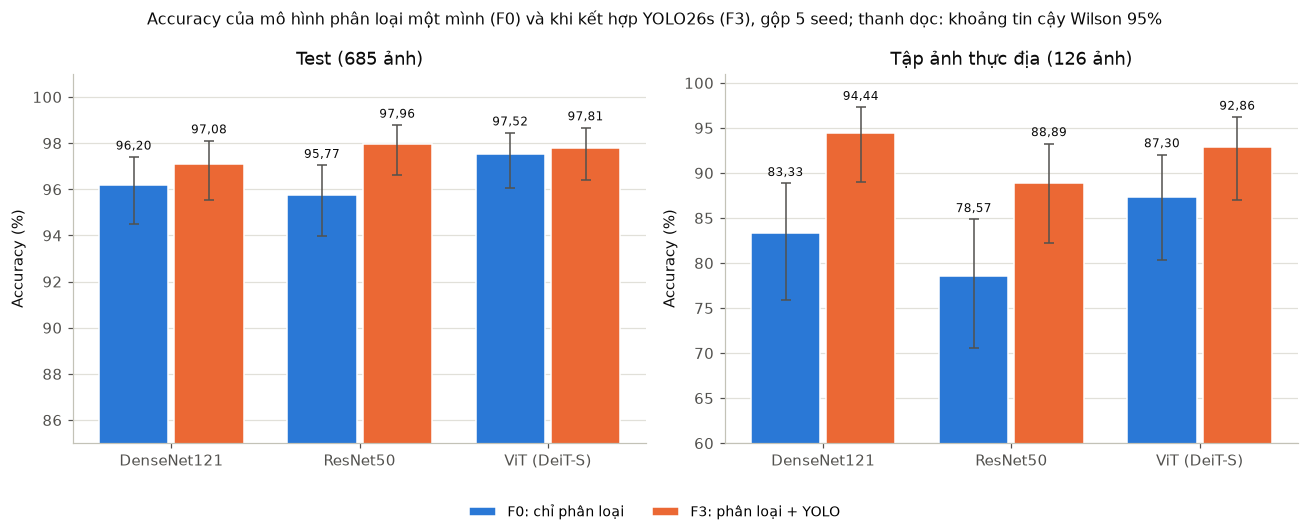

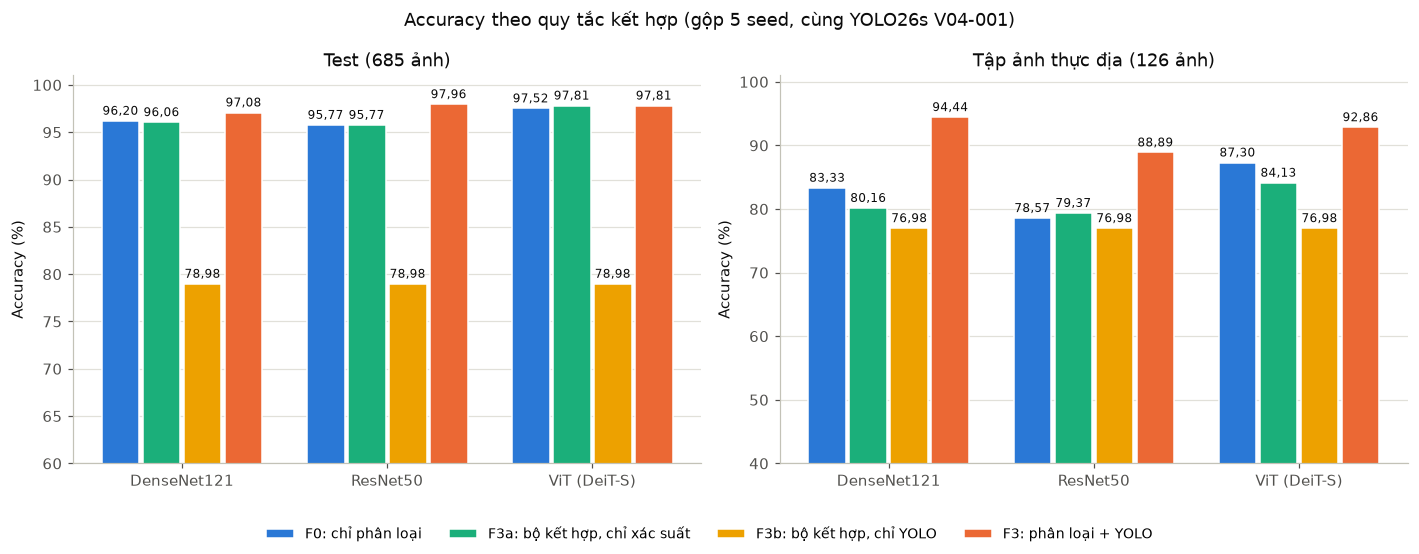

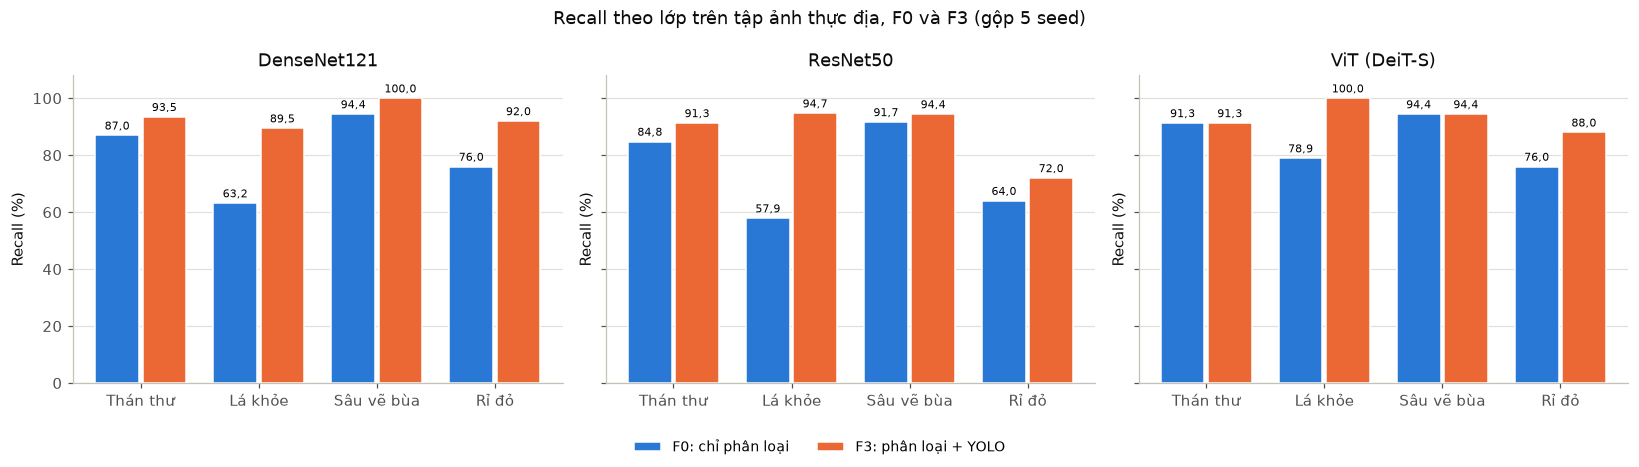

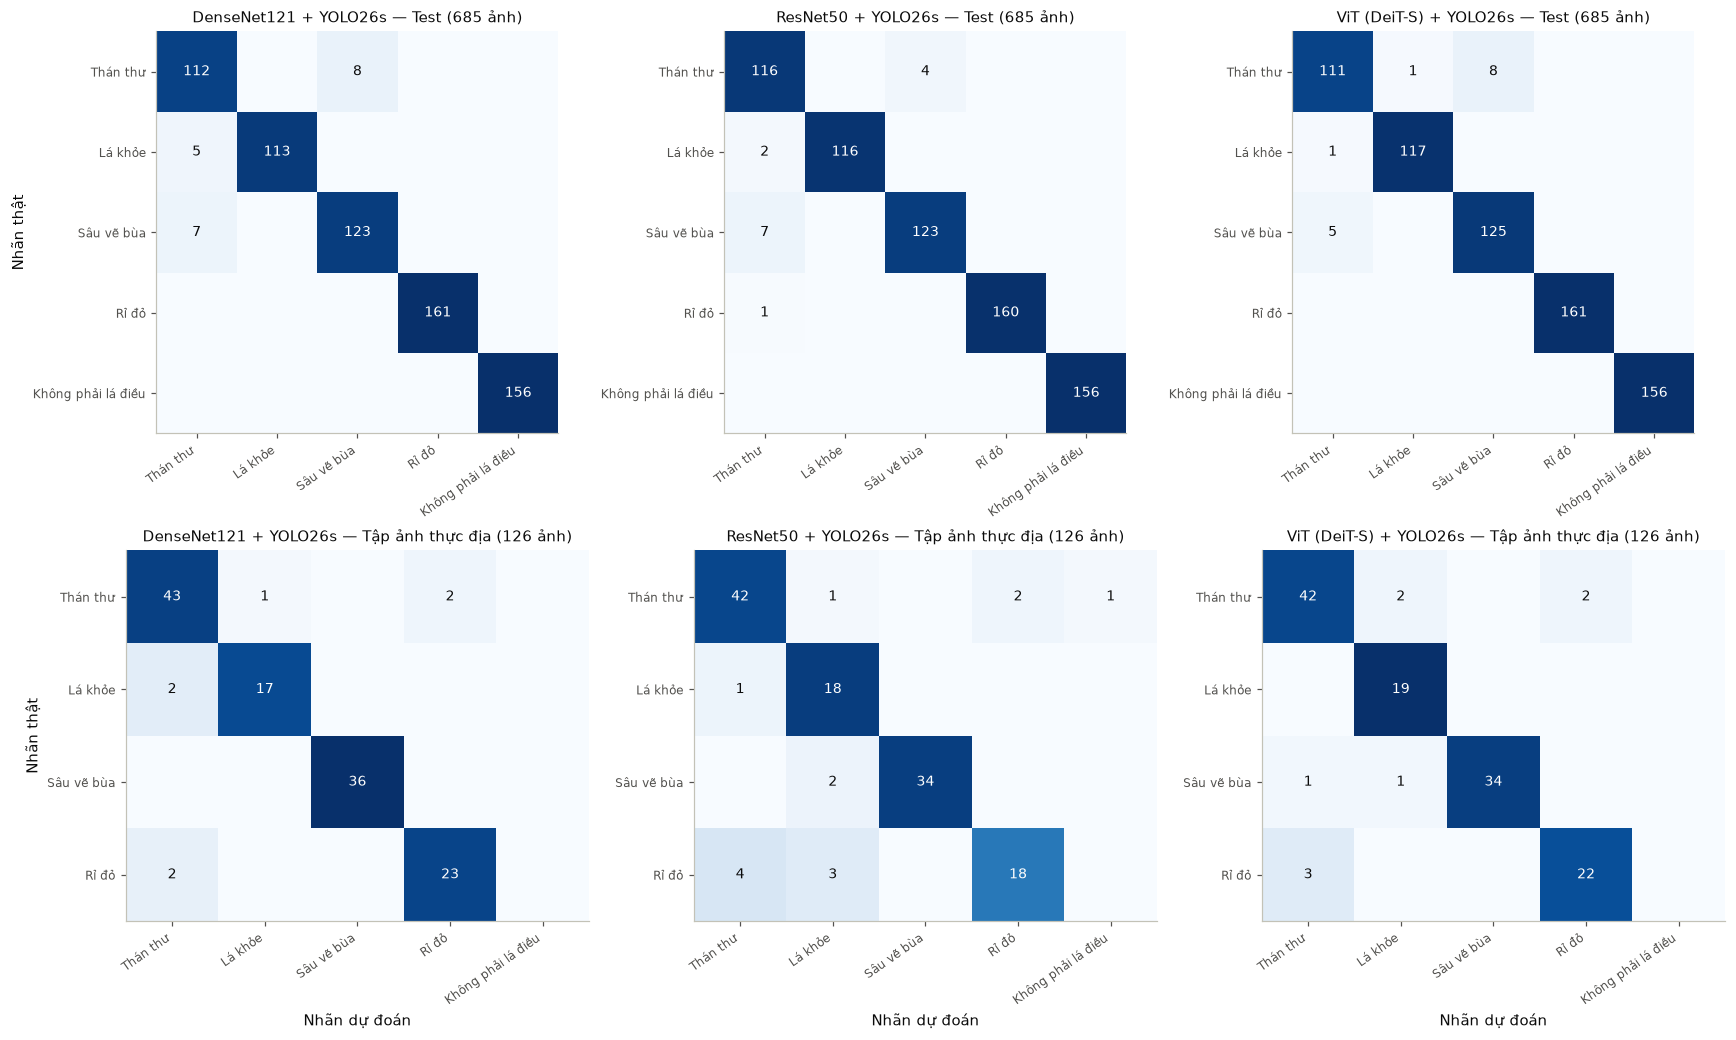

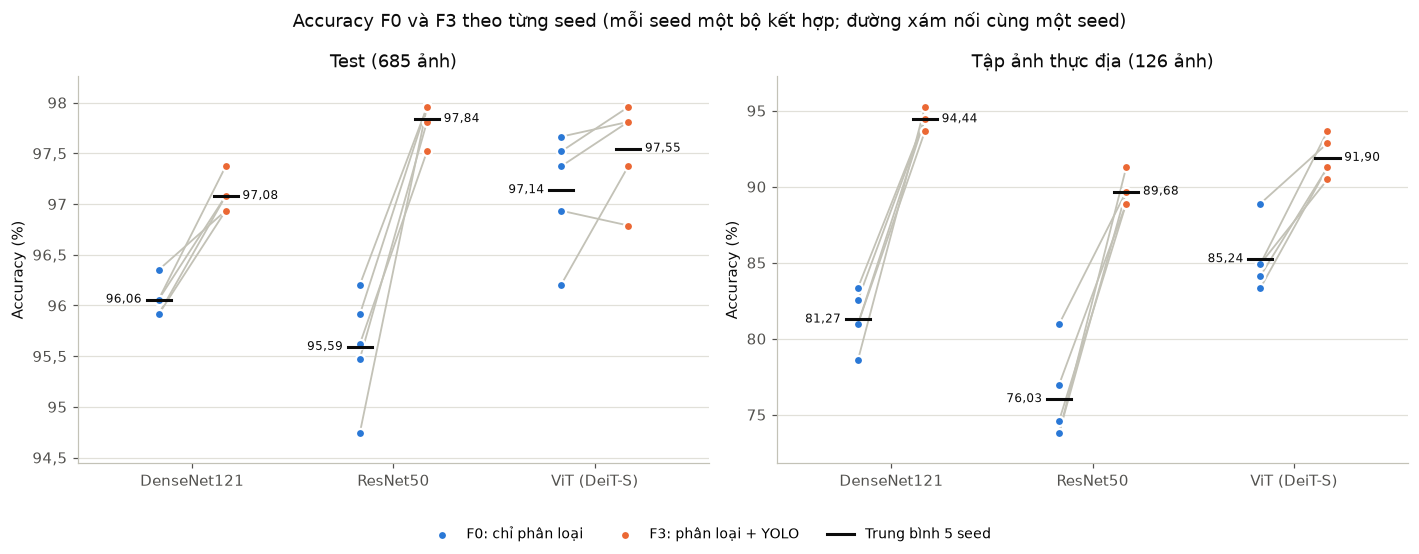

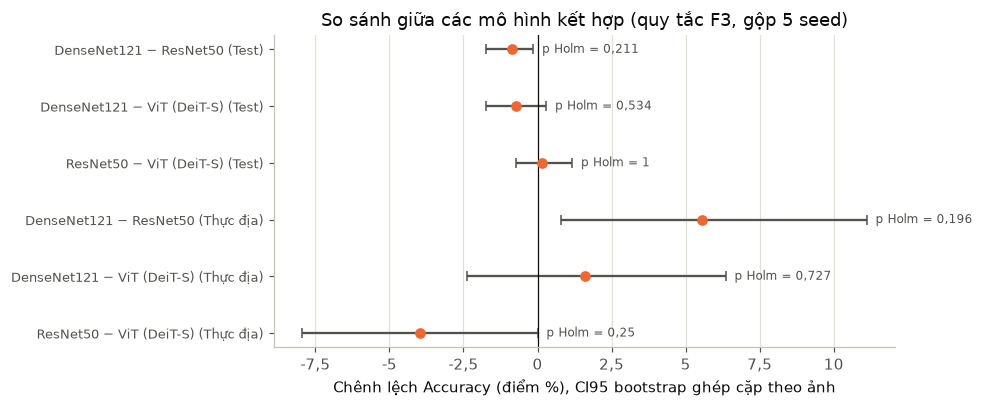

In [11]:
# 11. Biểu đồ (PNG 200 dpi, nền trắng)
RULE_COLOR = {"F0": "#2a78d6", "F3": "#eb6834", "F3a": "#1baf7a", "F3b": "#eda100"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
SPLIT_VN = {"test": "Test (685 ảnh)", "holdout": "Tập ảnh thực địa (126 ảnh)"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white"})

from matplotlib.ticker import FuncFormatter
COMMA = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))

def style(ax, ylabel="Accuracy (%)", ylim=None):
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, linewidth=.8)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(COMMA)
    if ylim:
        ax.set_ylim(*ylim)

def bottom_legend(fig, axes, ncol):
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=ncol, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, .08, 1, 1))

def grouped_bars(ax, rules, split, ylim, with_ci=False):
    x = np.arange(len(MODELS))
    width = .8 / len(rules)
    for k, rule in enumerate(rules):
        pos = x + (k - (len(rules) - 1) / 2) * width
        values = np.array([acc(m, rule, split) * 100 for m in MODELS])
        bars = ax.bar(pos, values, width * .92, color=RULE_COLOR[rule], label=RULE_LABEL[rule],
                      edgecolor="white", linewidth=1)
        text = [f"{v:.2f}".replace(".", ",") for v in values]
        if with_ci:
            low = np.array([acc(m, rule, split, "wilson_low") * 100 for m in MODELS])
            high = np.array([acc(m, rule, split, "wilson_high") * 100 for m in MODELS])
            ax.errorbar(pos, values, yerr=[values - low, high - values], fmt="none", ecolor=MUTED,
                        elinewidth=1, capsize=3)
            span = ylim[1] - ylim[0]
            for xi, hi, label in zip(pos, high, text):
                ax.text(xi, hi + span * .012, label, ha="center", va="bottom", fontsize=8, color=INK)
        else:
            ax.bar_label(bars, labels=text, fontsize=8, padding=2, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS)
    ax.set_title(SPLIT_VN[split], color=INK)
    style(ax, ylim=ylim)

# Hình 4.17: F0 và F3 (gộp 5 seed), kèm khoảng tin cậy Wilson 95%.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
grouped_bars(axes[0], ["F0", "F3"], "test", (85, 101), with_ci=True)
grouped_bars(axes[1], ["F0", "F3"], "holdout", (60, 101), with_ci=True)
fig.suptitle("Accuracy của mô hình phân loại một mình (F0) và khi kết hợp YOLO26s (F3), gộp 5 seed; "
             "thanh dọc: khoảng tin cậy Wilson 95%", color=INK, fontsize=10.5)
bottom_legend(fig, axes, 2)
fig.savefig(FIG / "hinh_4_17_F0_F3_gop5seed.png")
plt.show()

# Hình 4.18: bốn quy tắc.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
grouped_bars(axes[0], list(RULES), "test", (60, 101))
grouped_bars(axes[1], list(RULES), "holdout", (40, 101))
fig.suptitle("Accuracy theo quy tắc kết hợp (gộp 5 seed, cùng YOLO26s V04-001)", color=INK)
bottom_legend(fig, axes, 4)
fig.savefig(FIG / "hinh_4_18_quy_tac.png")
plt.show()

# Hình 4.19: Recall theo lớp trên tập ảnh thực địa.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, model in zip(axes, MODELS):
    part = per_class.query("model == @model and split == 'holdout'")
    x = np.arange(len(HOLDOUT_LABELS))
    for k, rule in enumerate(["F0", "F3"]):
        values = [float(part.query("rule == @rule and `class` == @c").recall.iloc[0]) * 100 for c in HOLDOUT_LABELS]
        bars = ax.bar(x + (k - .5) * .4, values, .37, color=RULE_COLOR[rule], label=RULE_LABEL[rule], edgecolor="white")
        ax.bar_label(bars, labels=[f"{v:.1f}".replace(".", ",") for v in values], fontsize=7.5, padding=2)
    ax.set_xticks(x)
    ax.set_xticklabels([CLASS_VN[c] for c in HOLDOUT_LABELS])
    ax.set_title(model, color=INK)
    style(ax, "Recall (%)", (0, 108))
fig.suptitle("Recall theo lớp trên tập ảnh thực địa, F0 và F3 (gộp 5 seed)", color=INK)
bottom_legend(fig, axes, 2)
fig.savefig(FIG / "hinh_4_19_recall_thuc_dia.png")
plt.show()

# Hình 4.20: ma trận nhầm lẫn F3 (gộp 5 seed).
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for row, split in enumerate(["test", "holdout"]):
    for col, model in enumerate(MODELS):
        ax = axes[row, col]
        part = PREDICTIONS_POOLED.query("model == @model and rule == 'F3' and split == @split")
        labels_true = CLASSES if split == "test" else HOLDOUT_LABELS
        cm = confusion_matrix(part.true_label, part.predicted_label, labels=CLASSES)
        cm = cm[[CLASS_INDEX[c] for c in labels_true]]
        share = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                if cm[i, j]:
                    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                            color="white" if share[i, j] > .6 else INK)
        ax.set_xticks(range(len(CLASSES)))
        ax.set_xticklabels([CLASS_VN[c] for c in CLASSES], rotation=35, ha="right", fontsize=8)
        ax.set_yticks(range(len(labels_true)))
        ax.set_yticklabels([CLASS_VN[c] for c in labels_true], fontsize=8)
        ax.set_title(f"{model} + YOLO26s — {SPLIT_VN[split]}", fontsize=9.5, color=INK)
        if col == 0:
            ax.set_ylabel("Nhãn thật")
        if row == 1:
            ax.set_xlabel("Nhãn dự đoán")
fig.tight_layout()
fig.savefig(FIG / "hinh_4_20_ma_tran_nham_lan_F3.png")
plt.show()

# Hình 4.21: F0 và F3 theo từng seed (mỗi đường là một seed).
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, split in zip(axes, ["test", "holdout"]):
    for i, model in enumerate(MODELS):
        part = SEED_RESULTS.query("model == @model and split == @split").pivot(index="seed", columns="rule", values="accuracy") * 100
        x0, x1 = i * 3, i * 3 + 1
        for seed, values in part.iterrows():
            ax.plot([x0, x1], [values["F0"], values["F3"]], color="#c3c2b7", linewidth=1.2, zorder=1)
        ax.scatter([x0] * len(part), part["F0"], s=36, color=RULE_COLOR["F0"], zorder=2,
                   label=RULE_LABEL["F0"] if i == 0 else None, edgecolor="white", linewidth=1.5)
        ax.scatter([x1] * len(part), part["F3"], s=36, color=RULE_COLOR["F3"], zorder=2,
                   label=RULE_LABEL["F3"] if i == 0 else None, edgecolor="white", linewidth=1.5)
        for x, rule, side in ((x0, "F0", -1), (x1, "F3", 1)):
            mean = part[rule].mean()
            ax.plot([x - .18, x + .18], [mean, mean], color=INK, linewidth=2, zorder=3,
                    label="Trung bình 5 seed" if (i == 0 and rule == "F0") else None)
            ax.text(x + side * .25, mean, f"{mean:.2f}".replace(".", ","), ha="left" if side > 0 else "right",
                    va="center", fontsize=8, color=INK)
    ax.set_xticks([i * 3 + .5 for i in range(len(MODELS))])
    ax.set_xticklabels(MODELS)
    ax.set_xlim(-1.2, 3 * (len(MODELS) - 1) + 2.2)
    ax.set_title(SPLIT_VN[split], color=INK)
    style(ax)
    low, high = ax.get_ylim()
    ax.set_ylim(low - (high - low) * .04, high + (high - low) * .04)
fig.suptitle("Accuracy F0 và F3 theo từng seed (mỗi seed một bộ kết hợp; đường xám nối cùng một seed)", color=INK)
bottom_legend(fig, axes, 3)
fig.savefig(FIG / "hinh_4_21_theo_seed.png")
plt.show()

# Hình bổ sung: chênh lệch Accuracy giữa các mô hình (F3, gộp 5 seed), CI95 bootstrap.
part = CROSS.query("rule == 'F3'").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3.8))
labels = [f"{r.model_a} − {r.model_b} ({'Test' if r.split == 'test' else 'Thực địa'})" for r in part.itertuples()]
y = np.arange(len(part))[::-1]
ax.errorbar(part.delta * 100, y, xerr=[(part.delta - part.ci_low) * 100, (part.ci_high - part.delta) * 100],
            fmt="o", color=RULE_COLOR["F3"], ecolor=MUTED, capsize=3)
for yi, r in zip(y, part.itertuples()):
    ax.text(r.ci_high * 100 + .3, yi, f"p Holm = {r.mcnemar_p_holm:.3g}".replace(".", ","), va="center",
            fontsize=8, color=MUTED)
ax.xaxis.set_major_formatter(COMMA)
ax.axvline(0, color=INK, linewidth=.8)
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=8.5)
ax.set_xlabel("Chênh lệch Accuracy (điểm %), CI95 bootstrap ghép cặp theo ảnh")
ax.grid(axis="x", color=GRID, linewidth=.8)
ax.set_title("So sánh giữa các mô hình kết hợp (quy tắc F3, gộp 5 seed)", color=INK)
fig.tight_layout()
fig.savefig(FIG / "hinh_bo_sung_chenh_lech_giua_mo_hinh.png")
plt.show()


## 12. README và đóng gói

Ghi `README.md` (bảng sẵn để chép vào khóa luận), `summary.json`, manifest SHA-256 và `*_ANALYSIS.zip`. Trên Colab, ZIP được upload lên thư mục Drive kết quả (không ghi đè file khác nội dung).

In [12]:
# 12. README tóm tắt và đóng gói ANALYSIS ZIP
def f2(value):
    return f"{value:.2f}".replace(".", ",")

def f4(value):
    return f"{value:.4f}".replace(".", ",")

lines = [f"# {EXPERIMENT_ID}", "",
         "Kết hợp YOLO26s (EXP-Y26S-NEG-V04-001) với ba mô hình phân loại theo **cùng một quy trình** "
         "(quy trình EXP-035, mục 3.7.5): gộp 5 seed, một bộ kết hợp hồi quy logistic chọn trên Validation sạch "
         f"({EXPECTED['clean_validation']} ảnh, GroupKFold theo nhóm pHash), temperature và ngưỡng từ chối chọn ngoài fold.", "",
         "| Mô hình phân loại | Thí nghiệm nguồn | ZIP (SHA-256) |", "|---|---|---|"]
lines += [f"| {m} | {INPUTS[m]['experiment']} | `{INPUTS[m]['archive']}` ({INPUTS[m]['sha256'][:12]}…) |" for m in MODELS]
dense_cfg = POOLED["DenseNet121"]
lines += ["", f"Tái lập EXP-035 (DenseNet121, gộp): **{'ĐẠT' if PARITY_PASS else 'KHÔNG ĐẠT'}**. F0 trùng tuyệt đối; "
          "F3 trong dung sai 2 ảnh. Bộ kết hợp F3 của DenseNet121 trong notebook này có "
          f"C = {dense_cfg['C']['F3']}, T = {f4(dense_cfg['temperature']['F3'])}, ngưỡng = {f4(dense_cfg['threshold']['F3'])}; "
          f"EXP-035/ứng dụng: C = {EXP035_CONFIG['C']['F3']}, T = {f4(EXP035_CONFIG['temperature']['F3'])}, "
          f"ngưỡng = {f4(EXP035_CONFIG['abstain_thresholds']['F3'])}. Khác biệt đến từ cách chia fold (xem `aggregate/parity_exp035.json`).",
          "", "## Bảng 4.13 (gộp 5 seed, Accuracy %)", "",
          "| Mô hình | Test F0 | Test F3 | Δ Test [CI95] | Thực địa F0 | Thực địa F3 | Δ Thực địa [CI95] |",
          "|---|---|---|---|---|---|---|"]
for r in TABLE_4_13.itertuples(index=False):
    lines.append(f"| {r[0]} | {f2(r[1])} | {f2(r[2])} | {f2(r[3])} [{f2(r[4])}; {f2(r[5])}] | {f2(r[6])} | {f2(r[7])} | "
                 f"{f2(r[8])} [{f2(r[9])}; {f2(r[10])}] |")
lines += ["", "## Accuracy theo quy tắc (gộp 5 seed, %)", "", "| Mô hình | Tập | F0 | F3a | F3b | F3 |", "|---|---|---|---|---|---|"]
for model in MODELS:
    for split, name in (("test", "Test"), ("holdout", "Thực địa")):
        lines.append(f"| {model} | {name} | " + " | ".join(f2(acc(model, r, split) * 100) for r in RULES) + " |")
lines += ["", "## Theo từng seed (trung bình ± SD, n = 5, %)", "", "| Mô hình | Test F0 | Test F3 | Thực địa F0 | Thực địa F3 |", "|---|---|---|---|---|"]
for model in MODELS:
    cells = []
    for split in ("test", "holdout"):
        for rule in ("F0", "F3"):
            r = SEED_SUMMARY.query("model == @model and rule == @rule and split == @split and metric == 'accuracy'").iloc[0]
            cells.append(f"{f2(r['mean'] * 100)} ± {f2(r['sd'] * 100)}")
    lines.append(f"| {model} | " + " | ".join(cells) + " |")
lines += ["", "## So sánh giữa các mô hình (F3, gộp 5 seed)", "", "| Cặp | Tập | Δ Accuracy [CI95] | Chỉ A đúng / chỉ B đúng | p McNemar (Holm) |", "|---|---|---|---|---|"]
for r in CROSS.query("rule == 'F3'").itertuples():
    lines.append(f"| {r.model_a} − {r.model_b} | {'Test' if r.split == 'test' else 'Thực địa'} | "
                 f"{f2(r.delta * 100)} [{f2(r.ci_low * 100)}; {f2(r.ci_high * 100)}] | {r.only_a_correct} / {r.only_b_correct} | "
                 f"{r.mcnemar_p:.3g} ({r.mcnemar_p_holm:.3g}) |")
lines += ["", "## Ghi chú", "",
          "- F3b chỉ dùng 9 đặc trưng YOLO nên giống nhau cho cả ba mô hình (cùng bằng chứng, cùng Validation sạch).",
          "- DenseNet121 ở đây là 5 mô hình của EXP-035 (giống ứng dụng), khác lần huấn luyện báo cáo ở mục 4.1.1.",
          "- Tập ảnh thực địa (Holdout 09) đã được xem trước: kết quả trên tập này chỉ mang tính mô tả.",
          "- Macro F1 trên tập ảnh thực địa tính trên 4 lớp có nhãn.",
          "- Bootstrap: 10.000 lần, đơn vị là ảnh; không phản ánh biến động do seed."]
README_TEXT = "\n".join(lines) + "\n"
(OUT_DIR / "README.md").write_text(README_TEXT, encoding="utf-8")
write_json(OUT_DIR / "summary.json", {"experiment": EXPERIMENT_ID, "parity_exp035": PARITY_PASS,
           "environment": ENVIRONMENT, "inputs": INPUTS, "detector": DETECTOR,
           "pooled": {m: {"C": b["C"], "temperature": b["temperature"], "threshold": b["threshold"]} for m, b in POOLED.items()}})
print(README_TEXT)

files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file())
manifest = [{"path": p.relative_to(OUT_DIR).as_posix(), "bytes": p.stat().st_size, "sha256": sha256_file(p)} for p in files]
write_json(OUT_DIR / "analysis_manifest.json", manifest)
analysis_zip = OUT_DIR.parent / f"{EXPERIMENT_ID}_ANALYSIS.zip"
with zipfile.ZipFile(analysis_zip, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as archive:
    for path in sorted(p for p in OUT_DIR.rglob("*") if p.is_file()):
        info = zipfile.ZipInfo(f"{EXPERIMENT_ID}/{path.relative_to(OUT_DIR).as_posix()}", date_time=(1980, 1, 1, 0, 0, 0))
        info.compress_type = zipfile.ZIP_DEFLATED
        archive.writestr(info, path.read_bytes())
with zipfile.ZipFile(analysis_zip) as archive:
    assert archive.testzip() is None
print("ANALYSIS ZIP:", analysis_zip, f"{analysis_zip.stat().st_size / 1e6:.1f} MB", "SHA-256", sha256_file(analysis_zip))

if UPLOAD_TO_DRIVE:
    from googleapiclient.http import MediaFileUpload
    service = drive_service(write=True)
    existing = service.files().list(q=f"name = '{analysis_zip.name}' and '{DRIVE_FOLDER_ID}' in parents and trashed = false",
                                    fields="files(id,size,md5Checksum)", supportsAllDrives=True,
                                    includeItemsFromAllDrives=True).execute().get("files", [])
    if existing:
        if existing[0].get("md5Checksum") != md5_file(analysis_zip):
            raise RuntimeError("Drive đã có ZIP cùng tên nhưng nội dung khác; không ghi đè.")
        print("Drive đã có đúng ZIP này:", existing[0]["id"])
    else:
        media = MediaFileUpload(str(analysis_zip), mimetype="application/zip", resumable=True)
        created = service.files().create(body={"name": analysis_zip.name, "parents": [DRIVE_FOLDER_ID]},
                                         media_body=media, fields="id,md5Checksum", supportsAllDrives=True).execute()
        assert created["md5Checksum"] == md5_file(analysis_zip)
        print("Đã upload:", f"https://drive.google.com/file/d/{created['id']}/view")


# EXP-COMBINED-3CLASSIFIERS-YOLO26S-V04-037

Kết hợp YOLO26s (EXP-Y26S-NEG-V04-001) với ba mô hình phân loại theo **cùng một quy trình** (quy trình EXP-035, mục 3.7.5): gộp 5 seed, một bộ kết hợp hồi quy logistic chọn trên Validation sạch (1361 ảnh, GroupKFold theo nhóm pHash), temperature và ngưỡng từ chối chọn ngoài fold.

| Mô hình phân loại | Thí nghiệm nguồn | ZIP (SHA-256) |
|---|---|---|
| DenseNet121 | EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04 | `EXP-DENSENET121-YOLO-COMBINED-TRAINING-035-NEGV04_ANALYSIS.zip` (27b5ea684d99…) |
| ResNet50 | EXP-RESNET50-TRANSFER-5SEEDS-031-256px-c954b7c4 | `EXP-RESNET50-TRANSFER-5SEEDS-031-256px-c954b7c4_ANALYSIS.zip` (85151ff0dbb9…) |
| ViT (DeiT-S) | EXP-VIT-DEITSMALL-TRANSFER-LLRD-5SEEDS-016-256px-1192fd08 | `EXP-VIT-DEITSMALL-TRANSFER-LLRD-5SEEDS-016-256px-1192fd08_FULL.zip` (e28040960bab…) |

Tái lập EXP-035 (DenseNet121, gộp): **ĐẠT**. F0 trùng tuyệt đối; F3 trong dung sai 2 ảnh. Bộ kết hợp F3 của DenseNet121 trong notebook này có 

ANALYSIS ZIP: D:\Study\KhoaLuanTotNghiep\Resource\training_results\current_dataset\EXP-COMBINED-3CLASSIFIERS-YOLO26S-V04-037_ANALYSIS.zip 2.3 MB SHA-256 eb80e77e33f89d910ccec39c3219c90fd281ccbe9b6ff460f417763ed4dbb5e0
